# RAG-Pipeline : Data ingestion to vector DB

In [1]:
import langchain
from langchain_community.document_loaders import PyPDFLoader , PyMuPDFLoader
from langchain_community.document_loaders import DirectoryLoader
from langchain_community.document_loaders import TextLoader
import os
from pathlib import Path



/tmp/ipykernel_2970/2838933081.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader , PyMuPDFLoader


In [2]:


from langchain_text_splitters import RecursiveCharacterTextSplitter

###  Read all the pdfs in the directory 

In [3]:
### Read all the pdf's inside the directory
def process_all_pdfs(pdf_directory):
    """Process all PDF files in a directory"""
    all_documents = []
    pdf_dir = Path(pdf_directory)
    
    # Find all PDF files recursively
    pdf_files = list(pdf_dir.glob("**/*.pdf"))
    
    print(f"Found {len(pdf_files)} PDF files to process")
    
    for pdf_file in pdf_files:
        print(f"\nProcessing: {pdf_file.name}")
        try:
            loader = PyPDFLoader(str(pdf_file))
            documents = loader.load()
            
            # Add source information to metadata
            for doc in documents:
                doc.metadata['source_file'] = pdf_file.name
                doc.metadata['file_type'] = 'pdf'
            
            all_documents.extend(documents)
            print(f"  ✓ Loaded {len(documents)} pages")
            
        except Exception as e:
            print(f"  ✗ Error: {e}")
    
    print(f"\nTotal documents loaded: {len(all_documents)}")
    return all_documents

# Process all PDFs in the data directory
all_pdf_documents = process_all_pdfs("../Data/pdf_files/Agri")

Found 11 PDF files to process

Processing: CWR-02-08-2021.pdf
  ✓ Loaded 7 pages

Processing: CWR-03-08-2021.pdf
  ✓ Loaded 8 pages

Processing: CWR-04-08-2021.pdf
  ✓ Loaded 8 pages

Processing: CWR-07-10-2021.pdf
  ✓ Loaded 8 pages

Processing: CWR-13-08-2020.pdf
  ✓ Loaded 7 pages

Processing: CWR-20-07-2021.pdf
  ✓ Loaded 9 pages

Processing: CWR-31-07-2021.pdf
  ✓ Loaded 9 pages

Processing: ICAR-En-Kharif-Agro-Advisories-for-Farmers-2025.pdf
  ✓ Loaded 310 pages

Processing: Kharif-agro-advisory-2021-final.pdf
  ✓ Loaded 400 pages

Processing: Kharif-agro-advisory-2022.pdf
  ✓ Loaded 442 pages

Processing: Rabi-Agro-Advisory-2021-22.pdf
  ✓ Loaded 755 pages

Total documents loaded: 1963


In [4]:
all_pdf_documents

[Document(metadata={'producer': 'www.ilovepdf.com', 'creator': 'Microsoft® Word 2016', 'creationdate': '2021-08-02T10:10:47+00:00', 'author': 'sarath chandra', 'moddate': '2021-08-02T10:10:49+00:00', 'source': '../Data/pdf_files/Agri/CWR-02-08-2021.pdf', 'total_pages': 7, 'page': 0, 'page_label': '1', 'source_file': 'CWR-02-08-2021.pdf', 'file_type': 'pdf'}, page_content='1 \n \nAll India Coordinated Research Project on Agrometeorology \nCRIDA, Santoshnagar, Hyderabad – 500 059 \nDaily Crop Weather Information as on 02 August 2021 \nAttention: Rajiv Maheshwari, OSD, ICAR  \nSignificant Weather Features (IMD) \n\uf0b7 The Well Marked Low Pressure Area over southeastern parts of West Uttar \nPradesh & neighbourhood now lies over southwest Uttar Pradesh & adjoining \nnorthwest Madhya Pradesh. The associated cyclonic circulation extends upto 7.6 \nkm above mean sea level. It is likely to move westwards gradually during next 3 \ndays.  \n\uf0b7 The monsoon trough has shifted slightly north 

###  text splitter get into chunks 

In [5]:
import re
from pathlib import Path
from typing import List

from langchain_core.documents import Document


# ============================================================
# CONFIGURATION
# ============================================================

DEFAULT_TARGET_SIZE = 1000       # Preferred chunk size in characters
DEFAULT_MIN_SIZE = 350           # Avoid very small chunks
DEFAULT_MAX_SIZE = 1500          # Hard maximum chunk size
DEFAULT_OVERLAP = 200            # Context overlap between chunks


# ============================================================
# TEXT CLEANING
# ============================================================

def clean_pdf_text(text: str) -> str:
    """
    Clean extracted PDF text while preserving useful structure.
    """

    if not text:
        return ""

    # Normalize different newline formats
    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")

    # Remove excessive spaces
    text = re.sub(r"[ \t]+", " ", text)

    # Remove excessive blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    # Fix spaces before punctuation
    text = re.sub(r"\s+([,.;:!?])", r"\1", text)

    # Normalize common bullet characters
    text = text.replace("•", "\n- ")
    text = text.replace("▪", "\n- ")
    text = text.replace("●", "\n- ")

    # Remove repeated page header/footer patterns where possible
    lines = []

    for line in text.splitlines():
        line = line.strip()

        if not line:
            lines.append("")
            continue

        # Ignore isolated page numbers
        if re.fullmatch(r"\d{1,4}", line):
            continue

        lines.append(line)

    text = "\n".join(lines)

    # Remove excessive blank lines again
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


# ============================================================
# HEADING DETECTION
# ============================================================

def is_heading(line: str) -> bool:
    """
    Detect likely headings in agricultural advisory documents.
    """

    line = line.strip()

    if not line:
        return False

    # Very long lines are probably normal content
    if len(line) > 180:
        return False

    # Common heading patterns
    heading_patterns = [
        r"^(chapter|section|part)\s+\d+",
        r"^\d+(\.\d+)*\s+[A-Z]",
        r"^[A-Z][A-Z\s\-:&/,()]{5,}$",
        r"^(crop|crops|soil|weather|irrigation|fertilizer|"
        r"pest|disease|diseases|harvesting|sowing|planting|"
        r"management|advisory|recommendation|precaution|"
        r"rice|wheat|cotton|sugarcane|soybean|maize|"
        r"groundnut|pulses|vegetables|fruits)\b",
    ]

    for pattern in heading_patterns:
        if re.search(pattern, line, flags=re.IGNORECASE):
            return True

    # Lines ending without punctuation and looking short
    if len(line.split()) <= 12 and not line.endswith((".", ",", ";", ":")):
        return True

    return False


# ============================================================
# SENTENCE SPLITTING
# ============================================================

def split_into_sentences(text: str) -> List[str]:
    """
    Split text into approximate sentences while preserving bullets.
    """

    if not text:
        return []

    # Keep bullet points as independent units
    text = re.sub(r"\n(?=[-•▪●])", "\n\n", text)

    # Split at sentence boundaries
    parts = re.split(
        r"(?<=[.!?])\s+(?=[A-Z0-9(])|\n{2,}",
        text
    )

    sentences = []

    for part in parts:
        part = re.sub(r"\s+", " ", part).strip()

        if part:
            sentences.append(part)

    return sentences


# ============================================================
# ADAPTIVE CHUNK CREATION
# ============================================================

def create_adaptive_chunks(
    text: str,
    target_size: int = DEFAULT_TARGET_SIZE,
    min_size: int = DEFAULT_MIN_SIZE,
    max_size: int = DEFAULT_MAX_SIZE,
    overlap: int = DEFAULT_OVERLAP,
) -> List[str]:
    """
    Create meaningful adaptive chunks.

    Strategy:
    - Preserve paragraphs and sentences.
    - Keep headings with following content.
    - Avoid chunks smaller than min_size where possible.
    - Never exceed max_size.
    - Add overlap for retrieval context.
    """

    text = clean_pdf_text(text)

    if not text:
        return []

    paragraphs = re.split(r"\n{2,}", text)

    units = []

    for paragraph in paragraphs:
        paragraph = paragraph.strip()

        if not paragraph:
            continue

        # Keep short headings attached to the next paragraph
        if is_heading(paragraph):
            units.append({
                "type": "heading",
                "text": paragraph
            })
        else:
            sentences = split_into_sentences(paragraph)

            for sentence in sentences:
                units.append({
                    "type": "content",
                    "text": sentence
                })

    chunks = []
    current_parts = []
    current_length = 0

    def flush_current_chunk():
        nonlocal current_parts, current_length

        if not current_parts:
            return

        chunk_text = " ".join(current_parts).strip()

        if chunk_text:
            chunks.append(chunk_text)

        current_parts = []
        current_length = 0

    for index, unit in enumerate(units):
        unit_text = unit["text"]
        unit_length = len(unit_text)

        # Add heading directly to the current chunk
        if unit["type"] == "heading":
            if current_length > 0 and current_length >= min_size:
                flush_current_chunk()

            current_parts.append(unit_text)
            current_length += unit_length
            continue

        # If adding the next sentence exceeds the maximum,
        # finalize the current chunk.
        if (
            current_length > 0
            and current_length + unit_length + 1 > max_size
        ):
            flush_current_chunk()

        current_parts.append(unit_text)
        current_length += unit_length + 1

        # Finalize once the target size is reached,
        # but only if the chunk is not too small.
        if current_length >= target_size:
            flush_current_chunk()

    flush_current_chunk()

    # Merge very small chunks with the previous chunk
    merged_chunks = []

    for chunk in chunks:
        if (
            merged_chunks
            and len(chunk) < min_size
            and len(merged_chunks[-1]) + len(chunk) + 1 <= max_size
        ):
            merged_chunks[-1] = (
                merged_chunks[-1] + " " + chunk
            ).strip()
        else:
            merged_chunks.append(chunk)

    # Add overlap between neighboring chunks
    final_chunks = []

    for index, chunk in enumerate(merged_chunks):
        if index == 0:
            final_chunks.append(chunk)
            continue

        previous_chunk = merged_chunks[index - 1]

        # Take the last overlap characters from previous chunk.
        # Start at a nearby word boundary.
        overlap_text = previous_chunk[-overlap:]

        first_space = overlap_text.find(" ")

        if first_space != -1:
            overlap_text = overlap_text[first_space + 1:]

        combined_chunk = (
            overlap_text + " " + chunk
        ).strip()

        # Do not exceed maximum size after overlap
        if len(combined_chunk) > max_size:
            combined_chunk = chunk

        final_chunks.append(combined_chunk)

    return final_chunks


# ============================================================
# METADATA EXTRACTION
# ============================================================

def infer_document_metadata(source_file: str) -> dict:
    """
    Infer broad metadata from the PDF filename.
    """

    filename = source_file.lower()

    metadata = {
        "document_category": "agricultural_advisory",
        "source_type": "pdf",
        "authority": "ICAR_or_agricultural_advisory_source",
    }

    if "kharif" in filename:
        metadata["season"] = "Kharif"

    elif "rabi" in filename:
        metadata["season"] = "Rabi"

    elif "cwr" in filename:
        metadata["document_category"] = "crop_weather_report"

    if "2025" in filename:
        metadata["document_year"] = 2025

    elif "2022" in filename:
        metadata["document_year"] = 2022

    elif "2021" in filename:
        metadata["document_year"] = 2021

    elif "2020" in filename:
        metadata["document_year"] = 2020

    return metadata


# ============================================================
# PAGE-LEVEL CHUNKING
# ============================================================

def split_documents_adaptive(
    documents: List[Document],
    target_size: int = DEFAULT_TARGET_SIZE,
    min_size: int = DEFAULT_MIN_SIZE,
    max_size: int = DEFAULT_MAX_SIZE,
    overlap: int = DEFAULT_OVERLAP,
) -> List[Document]:
    """
    Convert page-level PDF Documents into meaningful chunks.

    Every generated chunk preserves:
    - Original source file
    - Original page number
    - Source path
    - Document category
    - Season
    - Year
    - Chunk index
    - Total chunks from that page
    """

    all_chunks = []

    total_documents = len(documents)

    print("=" * 80)
    print("STARTING ADAPTIVE DOCUMENT CHUNKING")
    print("=" * 80)

    print(f"Input pages/documents : {total_documents}")
    print(f"Target chunk size     : {target_size} characters")
    print(f"Minimum chunk size    : {min_size} characters")
    print(f"Maximum chunk size    : {max_size} characters")
    print(f"Chunk overlap         : {overlap} characters")
    print()

    for document_index, document in enumerate(documents, start=1):

        raw_text = document.page_content

        if not raw_text or not raw_text.strip():
            print(
                f"Skipping empty document "
                f"{document_index}/{total_documents}"
            )
            continue

        source_file = document.metadata.get(
            "source_file",
            Path(
                document.metadata.get("source", "unknown.pdf")
            ).name
        )

        page_number = document.metadata.get(
            "page",
            document.metadata.get("page_number", None)
        )

        page_chunks = create_adaptive_chunks(
            text=raw_text,
            target_size=target_size,
            min_size=min_size,
            max_size=max_size,
            overlap=overlap,
        )

        document_metadata = infer_document_metadata(source_file)

        for chunk_index, chunk_text in enumerate(
            page_chunks,
            start=1
        ):

            chunk_metadata = dict(document.metadata)

            # Add inferred metadata
            chunk_metadata.update(document_metadata)

            # Add chunk-specific metadata
            chunk_metadata.update({
                "source_file": source_file,
                "page_number": page_number,
                "chunk_index": chunk_index,
                "chunks_from_page": len(page_chunks),
                "chunk_size": len(chunk_text),
                "chunking_method": "adaptive_sentence_aware",
                "chunk_target_size": target_size,
                "chunk_overlap": overlap,
            })

            chunk_document = Document(
                page_content=chunk_text,
                metadata=chunk_metadata
            )

            all_chunks.append(chunk_document)

        if document_index % 100 == 0:
            print(
                f"Processed {document_index}/{total_documents} pages | "
                f"Chunks created: {len(all_chunks)}"
            )

    print()
    print("=" * 80)
    print("ADAPTIVE CHUNKING COMPLETED")
    print("=" * 80)
    print(f"Input pages           : {total_documents}")
    print(f"Output chunks         : {len(all_chunks)}")

    if all_chunks:
        chunk_lengths = [
            len(chunk.page_content)
            for chunk in all_chunks
        ]

        average_size = sum(chunk_lengths) / len(chunk_lengths)

        print(f"Average chunk size    : {average_size:.2f} characters")
        print(f"Smallest chunk        : {min(chunk_lengths)} characters")
        print(f"Largest chunk         : {max(chunk_lengths)} characters")

        print()
        print("Example chunk:")
        print("-" * 80)
        print(all_chunks[0].page_content[:1000])
        print("-" * 80)

        print()
        print("Example metadata:")
        print(all_chunks[0].metadata)

    return all_chunks


# ============================================================
# RUN CHUNKING
# ============================================================

adaptive_chunks = split_documents_adaptive(
    documents=all_pdf_documents,
    target_size=1000,
    min_size=350,
    max_size=1500,
    overlap=200,
)

STARTING ADAPTIVE DOCUMENT CHUNKING
Input pages/documents : 1963
Target chunk size     : 1000 characters
Minimum chunk size    : 350 characters
Maximum chunk size    : 1500 characters
Chunk overlap         : 200 characters

Processed 100/1963 pages | Chunks created: 277
Processed 200/1963 pages | Chunks created: 789
Processed 300/1963 pages | Chunks created: 1309
Skipping empty document 366/1963
Skipping empty document 367/1963
Skipping empty document 368/1963
Processed 400/1963 pages | Chunks created: 1705
Processed 500/1963 pages | Chunks created: 1881
Processed 600/1963 pages | Chunks created: 2057
Processed 700/1963 pages | Chunks created: 2168
Skipping empty document 765/1963
Skipping empty document 766/1963
Skipping empty document 767/1963
Skipping empty document 768/1963
Skipping empty document 776/1963
Processed 800/1963 pages | Chunks created: 2304
Processed 900/1963 pages | Chunks created: 2539
Skipping empty document 964/1963
Processed 1000/1963 pages | Chunks created: 2719


Total chunks: 4012
Average size: 921.29
Median size: 1067.0
Minimum size: 2
Maximum size: 2872

Chunk size statistics:
count    4012.000000
mean      921.286142
std       466.212715
min         2.000000
25%       707.000000
50%      1067.000000
75%      1246.000000
max      2872.000000
dtype: float64


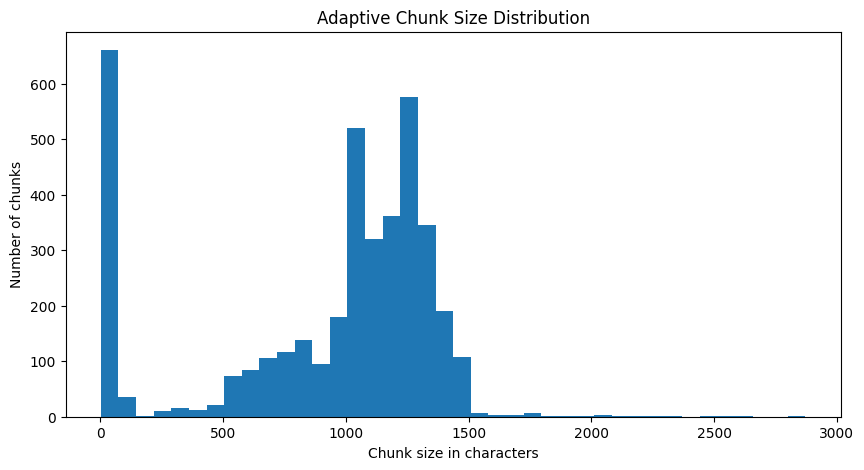

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

chunk_lengths = [
    len(chunk.page_content)
    for chunk in adaptive_chunks
]

chunk_stats = pd.Series(chunk_lengths)

print("Total chunks:", len(chunk_stats))
print("Average size:", round(chunk_stats.mean(), 2))
print("Median size:", round(chunk_stats.median(), 2))
print("Minimum size:", chunk_stats.min())
print("Maximum size:", chunk_stats.max())

print("\nChunk size statistics:")
print(chunk_stats.describe())

plt.figure(figsize=(10, 5))
plt.hist(chunk_lengths, bins=40)
plt.xlabel("Chunk size in characters")
plt.ylabel("Number of chunks")
plt.title("Adaptive Chunk Size Distribution")
plt.show()


In [7]:
import random

sample_count = min(5, len(adaptive_chunks))

for index in random.sample(range(len(adaptive_chunks)), sample_count):
    chunk = adaptive_chunks[index]

    print("=" * 100)
    print("CHUNK INDEX:", index)
    print("SOURCE:", chunk.metadata.get("source_file"))
    print("PAGE:", chunk.metadata.get("page_number"))
    print("CHUNK SIZE:", len(chunk.page_content))
    print("-" * 100)
    print(chunk.page_content[:1500])
    print()

CHUNK INDEX: 1700
SOURCE: Kharif-agro-advisory-2021-final.pdf
PAGE: 31
CHUNK SIZE: 1006
----------------------------------------------------------------------------------------------------
ICAR KHARIF AGRO-ADVISORY FOR FARMERS y Zn deficiency generally appears in maize in Zn deficit soils. where Zn deficiency has been noticed during previous years, apply 25 kg of zinc sulphate heptahydrate (21%) or 16.25 kg zinc sulphate monohydrate (33%) per ha at sowing. If Zn deficiency appear in the standing crop in the field, apply same quantity of Zn by mixing with an equal quantity of dry soil along rows and mix in the soil. y Pre-tasselling, silking and grain filling are the critical stages for irrigation. Ensure adequate water supply during these stages. Maize is very sensitive to water stagnation. In case of heavy rainfall, ensure drainage to avoid any stress to the crop. But if any damage occurs to the crop due to water stagnation, give two sprays of 3 % urea at weekly interval. If the damag

In [8]:
import re
import hashlib
from pathlib import Path
from collections import Counter

from langchain_core.documents import Document

In [9]:
# ---------------------------------------------------------
# Metadata enrichment configuration
# ---------------------------------------------------------

SUPPORTED_CROPS = {
    "rice",
    "paddy",
    "wheat",
    "maize",
    "corn",
    "sugarcane",
    "cotton",
    "soybean",
    "soyabean",
    "groundnut",
    "peanut",
    "chickpea",
    "gram",
    "chana",
    "pigeonpea",
    "pigeon peas",
    "tur",
    "red gram",
    "blackgram",
    "black gram",
    "greengram",
    "green gram",
    "mungbean",
    "moong",
    "lentil",
    "mustard",
    "rapeseed",
    "sunflower",
    "sesame",
    "jute",
    "potato",
    "onion",
    "tomato",
    "chilli",
    "chili",
    "brinjal",
    "eggplant",
    "okra",
    "bhindi",
    "banana",
    "mango",
    "grapes",
    "pomegranate",
    "orange",
    "papaya",
    "coconut",
    "coffee",
    "tea",
    "cashew",
    "turmeric",
    "ginger",
    "garlic",
    "cabbage",
    "cauliflower",
    "watermelon",
    "muskmelon",
    "apple",
}

INDIAN_STATES = {
    "andhra pradesh",
    "arunachal pradesh",
    "assam",
    "bihar",
    "chhattisgarh",
    "goa",
    "gujarat",
    "haryana",
    "himachal pradesh",
    "jharkhand",
    "karnataka",
    "kerala",
    "madhya pradesh",
    "maharashtra",
    "manipur",
    "meghalaya",
    "mizoram",
    "nagaland",
    "odisha",
    "orissa",
    "punjab",
    "rajasthan",
    "sikkim",
    "tamil nadu",
    "telangana",
    "tripura",
    "uttar pradesh",
    "uttarakhand",
    "west bengal",
    "jammu and kashmir",
    "ladakh",
    "delhi",
    "puducherry",
}

SEASONS = {
    "kharif",
    "rabi",
    "summer",
    "zaid",
    "monsoon",
    "post monsoon",
    "winter",
    "autumn",
}

TOPIC_KEYWORDS = {
    "weather": [
        "weather",
        "rainfall",
        "rain",
        "temperature",
        "humidity",
        "wind",
        "forecast",
        "cloud",
        "drought",
        "flood",
        "monsoon",
    ],
    "irrigation": [
        "irrigation",
        "water management",
        "water requirement",
        "drip",
        "sprinkler",
        "moisture",
        "watering",
        "irrigate",
    ],
    "soil": [
        "soil",
        "soil testing",
        "soil health",
        "ph",
        "nitrogen",
        "phosphorus",
        "potassium",
        "organic carbon",
        "salinity",
        "fertility",
    ],
    "fertilizer": [
        "fertilizer",
        "fertiliser",
        "manure",
        "urea",
        "dap",
        "mop",
        "nutrient",
        "nitrogen",
        "phosphorus",
        "potassium",
        "micronutrient",
    ],
    "pest": [
        "pest",
        "insect",
        "borer",
        "aphid",
        "whitefly",
        "thrips",
        "caterpillar",
        "beetle",
        "mite",
        "larva",
    ],
    "disease": [
        "disease",
        "fungus",
        "fungal",
        "bacterial",
        "viral",
        "blight",
        "wilt",
        "rust",
        "mildew",
        "rot",
        "spot",
        "virus",
    ],
    "weed_management": [
        "weed",
        "weeding",
        "herbicide",
        "weed management",
        "weed control",
    ],
    "seed_and_sowing": [
        "seed",
        "sowing",
        "planting",
        "transplanting",
        "germination",
        "nursery",
        "seed treatment",
        "spacing",
    ],
    "crop_management": [
        "crop management",
        "cultivation",
        "package of practices",
        "agronomy",
        "field preparation",
        "farm operation",
    ],
    "harvesting": [
        "harvest",
        "harvesting",
        "maturity",
        "mature",
        "post harvest",
        "storage",
        "grading",
        "packing",
    ],
    "market": [
        "market",
        "mandi",
        "price",
        "sale",
        "selling",
        "procurement",
        "marketing",
        "wholesale",
    ],
    "government_scheme": [
        "scheme",
        "subsidy",
        "government",
        "insurance",
        "pm kisan",
        "yojana",
        "benefit",
    ],
    "livestock": [
        "livestock",
        "cattle",
        "cow",
        "buffalo",
        "goat",
        "sheep",
        "poultry",
        "animal",
    ],
}

In [10]:
def normalize_text(text: str) -> str:
    """
    Normalize text for keyword matching.
    """
    if not text:
        return ""

    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def clean_metadata_value(value):
    """
    Convert metadata values into Chroma-compatible simple types.
    Chroma metadata should normally contain strings, numbers, or booleans.
    """
    if value is None:
        return None

    if isinstance(value, (str, int, float, bool)):
        return value

    if isinstance(value, list):
        return ", ".join(str(item) for item in value)

    if isinstance(value, tuple):
        return ", ".join(str(item) for item in value)

    if isinstance(value, dict):
        return str(value)

    return str(value)


def make_chunk_id(source_file: str, page_number, chunk_index: int, text: str):
    """
    Generate a stable unique ID for every chunk.
    """
    raw_id = (
        f"{source_file}|"
        f"{page_number}|"
        f"{chunk_index}|"
        f"{text[:300]}"
    )

    return hashlib.sha256(raw_id.encode("utf-8")).hexdigest()[:24]

In [11]:
def extract_year(source_file: str, text: str = ""):
    """
    Extract a relevant year from the filename first.
    If unavailable, search the chunk text.
    """

    source_file = str(source_file)

    # Prefer four-digit years in the filename
    filename_years = re.findall(r"\b(19\d{2}|20\d{2})\b", source_file)

    if filename_years:
        return int(filename_years[-1])

    # Fallback to text
    text_years = re.findall(r"\b(19\d{2}|20\d{2})\b", text)

    if text_years:
        return int(text_years[0])

    return None

In [12]:
def extract_seasons(text: str):
    """
    Return all seasons detected in the chunk.
    """
    normalized = normalize_text(text)

    found_seasons = []

    for season in SEASONS:
        if season in normalized:
            found_seasons.append(season)

    return sorted(set(found_seasons))

In [13]:
def extract_crops(text: str):
    """
    Extract crop names mentioned in the chunk.
    """
    normalized = normalize_text(text)

    found_crops = []

    for crop in SUPPORTED_CROPS:
        # Word-boundary matching prevents partial false matches
        pattern = rf"\b{re.escape(crop)}\b"

        if re.search(pattern, normalized):
            found_crops.append(crop)

    # Remove duplicates and sort by name
    return sorted(set(found_crops))

In [14]:
def extract_states(text: str):
    """
    Extract Indian state names mentioned in the chunk.
    """
    normalized = normalize_text(text)

    found_states = []

    for state in INDIAN_STATES:
        if state in normalized:
            found_states.append(state)

    return sorted(set(found_states))

In [17]:
def detect_topics(text: str):
    """
    Detect agricultural topics based on keyword groups.
    A chunk may belong to multiple topics.
    """
    normalized = normalize_text(text)

    detected_topics = []

    for topic, keywords in TOPIC_KEYWORDS.items():
        matched_keywords = []

        for keyword in keywords:
            if keyword in normalized:
                matched_keywords.append(keyword)

        if matched_keywords:
            detected_topics.append(topic)

    return sorted(set(detected_topics))

In [18]:
def detect_source_authority(source_file: str, text: str = ""):
    """
    Detect the likely source organization.
    """
    combined = normalize_text(f"{source_file} {text}")

    if "icar" in combined:
        return "ICAR"

    if "kisan call centre" in combined or "kcc" in combined:
        return "KCC"

    if "agromet" in combined or "agro advisory" in combined:
        return "Agromet Advisory"

    if "krishi vigyan kendra" in combined or "kvk" in combined:
        return "KVK"

    if "agriculture department" in combined:
        return "Agriculture Department"

    return "Unknown"

In [19]:
def detect_document_type(source_file: str, text: str = ""):
    """
    Classify the document into a broad document type.
    """
    combined = normalize_text(f"{source_file} {text}")

    if "agro-advisory" in combined or "agro advisory" in combined:
        return "agro_advisory"

    if "kharif" in combined:
        return "seasonal_advisory"

    if "rabi" in combined:
        return "seasonal_advisory"

    if "transcript" in combined or "query" in combined:
        return "farmer_query_answer"

    if "weather" in combined or "weather bulletin" in combined:
        return "weather_bulletin"

    if "crop calendar" in combined:
        return "crop_calendar"

    if "package of practices" in combined:
        return "package_of_practices"

    return "agricultural_document"

In [20]:
def detect_language(text: str):
    """
    Basic language detection.
    Most of your current documents appear to be English.
    """
    normalized = normalize_text(text)

    hindi_keywords = [
        "किसान",
        "फसल",
        "मौसम",
        "सिंचाई",
        "मिट्टी",
        "रोग",
    ]

    for keyword in hindi_keywords:
        if keyword in text:
            return "hi"

    # Simple English-character ratio
    if not text.strip():
        return "unknown"

    english_chars = len(re.findall(r"[a-zA-Z]", text))
    total_chars = len(re.sub(r"\s+", "", text))

    if total_chars == 0:
        return "unknown"

    english_ratio = english_chars / total_chars

    if english_ratio > 0.65:
        return "en"

    return "mixed"

In [21]:
def extract_agricultural_entities(text: str):
    """
    Extract important numerical and agricultural entities.
    """
    entities = {}

    normalized = normalize_text(text)

    # Rainfall values
    rainfall_matches = re.findall(
        r"(\d+(?:\.\d+)?)\s*(?:mm|millimetre|millimeter)",
        normalized,
    )

    if rainfall_matches:
        entities["rainfall_values_mm"] = rainfall_matches[:10]

    # Temperature values
    temperature_matches = re.findall(
        r"(\d+(?:\.\d+)?)\s*(?:°c|degrees c|degree c|celsius)",
        normalized,
    )

    if temperature_matches:
        entities["temperature_values_c"] = temperature_matches[:10]

    # Soil pH values
    ph_matches = re.findall(
        r"\bph\s*(?:value|of|is|:)?\s*(\d+(?:\.\d+)?)",
        normalized,
    )

    if ph_matches:
        entities["ph_values"] = ph_matches[:10]

    # Percentage values
    percentage_matches = re.findall(
        r"(\d+(?:\.\d+)?)\s*%",
        normalized,
    )

    if percentage_matches:
        entities["percentage_values"] = percentage_matches[:10]

    # Crop growth stages
    growth_stages = [
        "germination",
        "seedling",
        "vegetative",
        "flowering",
        "fruiting",
        "grain filling",
        "maturity",
        "harvesting",
    ]

    detected_stages = [
        stage for stage in growth_stages
        if stage in normalized
    ]

    if detected_stages:
        entities["growth_stages"] = detected_stages

    return entities

In [22]:
def enrich_document_metadata(
    document: Document,
    chunk_index: int,
    total_chunks: int,
):
    """
    Enrich one LangChain Document with structured metadata.

    The original page_content is preserved.
    Only metadata is updated.
    """

    text = document.page_content or ""
    original_metadata = dict(document.metadata or {})

    source_file = (
        original_metadata.get("source_file")
        or original_metadata.get("file_name")
        or original_metadata.get("source")
        or "unknown_source"
    )

    source_path = original_metadata.get("source_path", "")
    page_number = original_metadata.get("page")

    # PyPDFLoader generally uses zero-based page numbers.
    # Store a human-friendly one-based page number separately.
    if isinstance(page_number, int):
        page_number_display = page_number + 1
    else:
        page_number_display = None

    crops = extract_crops(text)
    states = extract_states(text)
    seasons = extract_seasons(text)
    topics = detect_topics(text)
    year = extract_year(source_file, text)
    authority = detect_source_authority(source_file, text)
    document_type = detect_document_type(source_file, text)
    language = detect_language(text)
    entities = extract_agricultural_entities(text)

    chunk_id = make_chunk_id(
        source_file=source_file,
        page_number=page_number_display,
        chunk_index=chunk_index,
        text=text,
    )

    enriched_metadata = {
        # Original source information
        **original_metadata,

        # Stable chunk identity
        "chunk_id": chunk_id,
        "chunk_index": chunk_index,
        "total_chunks": total_chunks,

        # File information
        "source_file": str(source_file),
        "source_path": str(source_path),
        "file_type": "pdf",
        "document_type": document_type,

        # Page information
        "page_zero_based": page_number,
        "page_number": page_number_display,

        # Source and authority
        "source_authority": authority,
        "source_year": year,

        # Agricultural filters
        "crops": ", ".join(crops) if crops else "general",
        "states": ", ".join(states) if states else "general",
        "seasons": ", ".join(seasons) if seasons else "all_seasons",
        "topics": ", ".join(topics) if topics else "general",

        # Language and text statistics
        "language": language,
        "character_count": len(text),
        "word_count": len(text.split()),

        # Searchable entity information
        "agricultural_entities": str(entities),
    }

    # Remove None values because some vector stores do not accept them.
    enriched_metadata = {
        key: clean_metadata_value(value)
        for key, value in enriched_metadata.items()
        if value is not None
    }

    document.metadata = enriched_metadata

    return document

In [23]:
def enrich_all_documents(documents):
    """
    Enrich every chunk with metadata.
    """
    enriched_documents = []

    total_chunks = len(documents)

    print("=" * 80)
    print("STARTING METADATA ENRICHMENT")
    print("=" * 80)

    for index, document in enumerate(documents):
        try:
            enriched_document = enrich_document_metadata(
                document=document,
                chunk_index=index,
                total_chunks=total_chunks,
            )

            enriched_documents.append(enriched_document)

        except Exception as error:
            print(
                f"Metadata enrichment failed for chunk "
                f"{index}: {error}"
            )

    print(f"\nInput chunks: {len(documents)}")
    print(f"Enriched chunks: {len(enriched_documents)}")

    if enriched_documents:
        print("\nExample enriched metadata:")
        print(enriched_documents[0].metadata)

    return enriched_documents

In [26]:
enriched_chunks = enrich_all_documents(adaptive_chunks)

STARTING METADATA ENRICHMENT

Input chunks: 4012
Enriched chunks: 4012

Example enriched metadata:
{'producer': 'www.ilovepdf.com', 'creator': 'Microsoft® Word 2016', 'creationdate': '2021-08-02T10:10:47+00:00', 'author': 'sarath chandra', 'moddate': '2021-08-02T10:10:49+00:00', 'source': '../Data/pdf_files/Agri/CWR-02-08-2021.pdf', 'total_pages': 7, 'page': 0, 'page_label': '1', 'source_file': 'CWR-02-08-2021.pdf', 'file_type': 'pdf', 'document_category': 'crop_weather_report', 'source_type': 'pdf', 'authority': 'ICAR_or_agricultural_advisory_source', 'document_year': 2021, 'page_number': 1, 'chunk_index': 0, 'chunks_from_page': 2, 'chunk_size': 1061, 'chunking_method': 'adaptive_sentence_aware', 'chunk_target_size': 1000, 'chunk_overlap': 200, 'chunk_id': '4b9db0c96544a4627f0adbb4', 'total_chunks': 4012, 'source_path': '', 'document_type': 'weather_bulletin', 'page_zero_based': 0, 'source_authority': 'ICAR', 'source_year': 2021, 'crops': 'general', 'states': 'madhya pradesh, rajastha

In [27]:
def inspect_enriched_chunks(documents, number_of_chunks=5):
    """
    Display sample chunks and their metadata.
    """
    print("=" * 80)
    print("ENRICHED CHUNK INSPECTION")
    print("=" * 80)

    for index, document in enumerate(documents[:number_of_chunks]):
        print(f"\n{'-' * 80}")
        print(f"CHUNK {index + 1}")
        print(f"{'-' * 80}")

        print("\nContent preview:")
        print(document.page_content[:500])

        print("\nMetadata:")
        for key, value in document.metadata.items():
            print(f"{key}: {value}")

In [28]:
inspect_enriched_chunks(
    enriched_chunks,
    number_of_chunks=5,
)

ENRICHED CHUNK INSPECTION

--------------------------------------------------------------------------------
CHUNK 1
--------------------------------------------------------------------------------

Content preview:
All India Coordinated Research Project on Agrometeorology CRIDA, Santoshnagar, Hyderabad – 500 059 Daily Crop Weather Information as on 02 August 2021 Attention: Rajiv Maheshwari, OSD, ICAR Significant Weather Features (IMD)  The Well Marked Low Pressure Area over southeastern parts of West Uttar Pradesh & neighbourhood now lies over southwest Uttar Pradesh & adjoining northwest Madhya Pradesh. The associated cyclonic circulation extends upto 7.6 km above mean sea level. It is likely to move we

Metadata:
producer: www.ilovepdf.com
creator: Microsoft® Word 2016
creationdate: 2021-08-02T10:10:47+00:00
author: sarath chandra
moddate: 2021-08-02T10:10:49+00:00
source: ../Data/pdf_files/Agri/CWR-02-08-2021.pdf
total_pages: 7
page: 0
page_label: 1
source_file: CWR-02-08-2021.pdf

In [29]:
def metadata_distribution(documents, metadata_key):
    """
    Show the most common values for a metadata field.
    """
    values = []

    for document in documents:
        value = document.metadata.get(metadata_key)

        if value:
            values.append(str(value))

    counts = Counter(values)

    print(f"\nMetadata distribution: {metadata_key}")
    print("-" * 60)

    for value, count in counts.most_common(20):
        print(f"{count:6} | {value}")

    return counts

In [30]:
metadata_distribution(
    enriched_chunks,
    "source_authority",
)

metadata_distribution(
    enriched_chunks,
    "document_type",
)

metadata_distribution(
    enriched_chunks,
    "seasons",
)

metadata_distribution(
    enriched_chunks,
    "topics",
)


Metadata distribution: source_authority
------------------------------------------------------------
  3152 | ICAR
   828 | Unknown
    30 | KVK
     2 | Agromet Advisory

Metadata distribution: document_type
------------------------------------------------------------
  2642 | agro_advisory
  1296 | seasonal_advisory
    47 | weather_bulletin
    27 | agricultural_document

Metadata distribution: seasons
------------------------------------------------------------
  1345 | all_seasons
  1003 | kharif
   715 | rabi
   219 | monsoon
   140 | kharif, monsoon
   134 | summer
    99 | kharif, summer
    67 | rabi, winter
    47 | winter
    41 | monsoon, summer
    36 | kharif, monsoon, summer
    25 | rabi, summer
    24 | kharif, rabi
    17 | summer, winter
    15 | monsoon, rabi
    15 | kharif, monsoon, rabi
    11 | rabi, summer, winter
    10 | kharif, winter
     9 | kharif, rabi, summer
     7 | autumn

Metadata distribution: topics
-----------------------------------------------

Counter({'general': 763,
         'disease, livestock, weather': 59,
         'disease, fertilizer, pest, seed_and_sowing, soil': 56,
         'disease, pest, seed_and_sowing, soil': 53,
         'disease, fertilizer, irrigation, pest, seed_and_sowing, soil, weather, weed_management': 43,
         'weather': 40,
         'disease, fertilizer, pest, seed_and_sowing, soil, weather': 40,
         'soil, weather': 39,
         'disease, fertilizer, irrigation, pest, seed_and_sowing, soil, weather': 38,
         'disease, fertilizer, pest, seed_and_sowing, soil, weed_management': 36,
         'disease, livestock': 35,
         'fertilizer, irrigation, seed_and_sowing, soil, weather': 32,
         'disease, fertilizer, seed_and_sowing, soil, weather': 29,
         'disease, fertilizer, irrigation, seed_and_sowing, soil, weather': 29,
         'livestock': 27,
         'disease, seed_and_sowing, soil': 27,
         'disease, fertilizer, irrigation, seed_and_sowing, soil': 26,
         'diseas

In [31]:
def find_chunks_by_crop(documents, crop_name):
    """
    Find chunks mentioning a particular crop.
    """
    crop_name = crop_name.lower().strip()

    matching_documents = []

    for document in documents:
        crops = str(
            document.metadata.get("crops", "")
        ).lower()

        content = document.page_content.lower()

        if crop_name in crops or crop_name in content:
            matching_documents.append(document)

    print(
        f"Found {len(matching_documents)} chunks "
        f"related to: {crop_name}"
    )

    return matching_documents

In [32]:
sugarcane_chunks = find_chunks_by_crop(
    enriched_chunks,
    "sugarcane",
)

Found 143 chunks related to: sugarcane


In [33]:
rice_chunks = find_chunks_by_crop(
    enriched_chunks,
    "rice",
)

cotton_chunks = find_chunks_by_crop(
    enriched_chunks,
    "cotton",
)

maize_chunks = find_chunks_by_crop(
    enriched_chunks,
    "maize",
)

Found 591 chunks related to: rice
Found 254 chunks related to: cotton
Found 448 chunks related to: maize


In [34]:
import json


def save_enriched_metadata(documents, output_path):
    """
    Save chunk metadata and content previews to JSON.
    """
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    records = []

    for document in documents:
        records.append({
            "page_content_preview": document.page_content[:500],
            "metadata": document.metadata,
        })

    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(
            records,
            file,
            ensure_ascii=False,
            indent=2,
        )

    print(f"Saved metadata inspection file: {output_path}")

In [35]:
save_enriched_metadata(
    enriched_chunks,
    "../Data/metadata/enriched_chunk_metadata.json",
)

Saved metadata inspection file: ../Data/metadata/enriched_chunk_metadata.json


### Embedding  And Vector Store DB

In [8]:

from sentence_transformers import SentenceTransformer

import numpy as np
import chromadb
from chromadb.config import Settings
import os
from typing import List, Dict, Any, Tuple
from sklearn.metrics.pairwise import cosine_similarity
import uuid


In [39]:
# ============================================================
# IMPROVED AGRICULTURAL RAG EMBEDDING PIPELINE
# PDF CHUNKS -> METADATA-AWARE TEXT -> EMBEDDINGS
# ============================================================

from pathlib import Path
from typing import List, Dict, Any, Optional
from collections import Counter
import json
import hashlib
import re

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer


# ============================================================
# CONFIGURATION
# ============================================================

EMBEDDING_MODEL_NAME = "BAAI/bge-small-en-v1.5"

# Your project directories
PROJECT_ROOT = Path("/mnt/d/EdgeAi_resistor_Dl_model/RAG/ml_training")

# Change this if your RAG notebook is running from another location
RAG_ROOT = Path("../Data")

EMBEDDING_OUTPUT_DIR = RAG_ROOT / "embeddings"

EMBEDDING_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EMBEDDINGS_FILE = EMBEDDING_OUTPUT_DIR / "agri_embeddings.npy"
RECORDS_FILE = EMBEDDING_OUTPUT_DIR / "agri_embedding_records.jsonl"
MANIFEST_FILE = EMBEDDING_OUTPUT_DIR / "embedding_manifest.json"

# Embedding generation settings
BATCH_SIZE = 32
NORMALIZE_EMBEDDINGS = True

# Maximum characters used from one chunk for embedding.
# The original page_content is still preserved separately.
MAX_CONTENT_CHARACTERS = 5000

# Minimum meaningful content length
MIN_CONTENT_CHARACTERS = 80


# ============================================================
# TEXT CLEANING
# ============================================================

def clean_text(text: Any) -> str:
    """
    Clean PDF-extracted text without destroying its meaning.
    """

    if text is None:
        return ""

    text = str(text)

    # Replace null bytes
    text = text.replace("\x00", " ")

    # Normalize common whitespace
    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")
    text = text.replace("\t", " ")

    # Remove excessive spaces
    text = re.sub(r"[ ]{2,}", " ", text)

    # Remove excessive blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    # Remove spaces around line breaks
    text = re.sub(r" *\n *", "\n", text)

    return text.strip()


def clean_metadata_value(value: Any) -> str:
    """
    Convert metadata values into readable text.
    Supports strings, lists, tuples, sets, and numbers.
    """

    if value is None:
        return ""

    if isinstance(value, (list, tuple, set)):
        values = []

        for item in value:
            item_text = clean_text(item)

            if item_text:
                values.append(item_text)

        return ", ".join(values)

    if isinstance(value, dict):
        values = []

        for key, item in value.items():
            item_text = clean_metadata_value(item)

            if item_text:
                values.append(f"{key}: {item_text}")

        return "; ".join(values)

    return clean_text(value)


# ============================================================
# METADATA EXTRACTION
# ============================================================

def get_metadata_value(
    metadata: Dict[str, Any],
    possible_keys: List[str],
    default: str = ""
) -> str:
    """
    Get the first available value from multiple possible metadata keys.
    """

    for key in possible_keys:
        if key in metadata:
            value = clean_metadata_value(metadata.get(key))

            if value:
                return value

    return default


def normalize_chunk_metadata(
    chunk: Any,
    chunk_index: int
) -> Dict[str, Any]:
    """
    Normalize metadata from a LangChain Document.

    This function supports your existing enriched_chunks list.
    """

    raw_metadata = getattr(chunk, "metadata", {}) or {}

    page_content = clean_text(
        getattr(chunk, "page_content", "")
    )

    source_file = get_metadata_value(
        raw_metadata,
        [
            "source_file",
            "source",
            "file_name",
            "filename"
        ],
        default="unknown"
    )

    page_number = get_metadata_value(
        raw_metadata,
        [
            "page",
            "page_number",
            "page_num"
        ],
        default=""
    )

    source_authority = get_metadata_value(
        raw_metadata,
        [
            "source_authority",
            "authority",
            "organization",
            "publisher"
        ],
        default="unknown"
    )

    document_type = get_metadata_value(
        raw_metadata,
        [
            "document_type",
            "doc_type",
            "file_type"
        ],
        default="unknown"
    )

    crops = get_metadata_value(
        raw_metadata,
        [
            "crops",
            "crop",
            "crop_names",
            "crop_name"
        ],
        default=""
    )

    seasons = get_metadata_value(
        raw_metadata,
        [
            "seasons",
            "season"
        ],
        default=""
    )

    states = get_metadata_value(
        raw_metadata,
        [
            "states",
            "state"
        ],
        default=""
    )

    districts = get_metadata_value(
        raw_metadata,
        [
            "districts",
            "district"
        ],
        default=""
    )

    topics = get_metadata_value(
        raw_metadata,
        [
            "topics",
            "topic"
        ],
        default=""
    )

    languages = get_metadata_value(
        raw_metadata,
        [
            "languages",
            "language"
        ],
        default=""
    )

    published_date = get_metadata_value(
        raw_metadata,
        [
            "published_date",
            "publication_date",
            "date"
        ],
        default=""
    )

    # Use the original chunk ID if metadata enrichment created one.
    existing_chunk_id = get_metadata_value(
        raw_metadata,
        [
            "chunk_id",
            "id",
            "document_id"
        ],
        default=""
    )

    if existing_chunk_id:
        chunk_id = existing_chunk_id
    else:
        unique_text = (
            f"{source_file}|"
            f"{page_number}|"
            f"{chunk_index}|"
            f"{page_content}"
        )

        chunk_id = hashlib.sha1(
            unique_text.encode("utf-8")
        ).hexdigest()

    normalized_metadata = {
        "chunk_id": chunk_id,
        "source_file": source_file,
        "page_number": page_number,
        "source_authority": source_authority,
        "document_type": document_type,
        "crops": crops,
        "seasons": seasons,
        "states": states,
        "districts": districts,
        "topics": topics,
        "languages": languages,
        "published_date": published_date,
        "chunk_index": chunk_index,
        "content_length": len(page_content),
    }

    return {
        "chunk_id": chunk_id,
        "page_content": page_content,
        "metadata": normalized_metadata,
        "original_metadata": raw_metadata,
    }


# ============================================================
# DUPLICATE DETECTION
# ============================================================

def calculate_text_hash(text: str) -> str:
    """
    Generate a stable hash for duplicate detection.
    """

    normalized = re.sub(
        r"\s+",
        " ",
        text.lower()
    ).strip()

    return hashlib.sha1(
        normalized.encode("utf-8")
    ).hexdigest()


def remove_duplicate_chunks(
    records: List[Dict[str, Any]]
) -> List[Dict[str, Any]]:
    """
    Remove exact duplicate content while preserving metadata.
    """

    unique_records = []
    seen_hashes = set()

    duplicate_count = 0

    for record in records:
        content = record["page_content"]

        content_hash = calculate_text_hash(content)

        if content_hash in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes.add(content_hash)

        record["metadata"]["content_hash"] = content_hash

        unique_records.append(record)

    print(f"Duplicate chunks removed: {duplicate_count}")
    print(f"Unique chunks remaining: {len(unique_records)}")

    return unique_records


# ============================================================
# MEANINGFUL METADATA-AWARE EMBEDDING TEXT
# ============================================================

def build_embedding_text(
    record: Dict[str, Any]
) -> str:
    """
    Build the text that will actually be embedded.

    Important:
    - Metadata is included as readable context.
    - Full metadata is not blindly dumped into the embedding.
    - The original page_content is preserved separately.
    """

    metadata = record["metadata"]
    page_content = record["page_content"]

    # Limit very large chunks for embedding stability.
    page_content_for_embedding = page_content[
        :MAX_CONTENT_CHARACTERS
    ]

    sections = []

    if metadata.get("source_authority"):
        sections.append(
            f"Source authority: {metadata['source_authority']}"
        )

    if metadata.get("document_type"):
        sections.append(
            f"Document type: {metadata['document_type']}"
        )

    if metadata.get("source_file"):
        sections.append(
            f"Source document: {metadata['source_file']}"
        )

    if metadata.get("page_number"):
        sections.append(
            f"Page number: {metadata['page_number']}"
        )

    if metadata.get("crops"):
        sections.append(
            f"Crop: {metadata['crops']}"
        )

    if metadata.get("seasons"):
        sections.append(
            f"Season: {metadata['seasons']}"
        )

    if metadata.get("states"):
        sections.append(
            f"State or region: {metadata['states']}"
        )

    if metadata.get("districts"):
        sections.append(
            f"District: {metadata['districts']}"
        )

    if metadata.get("topics"):
        sections.append(
            f"Topic: {metadata['topics']}"
        )

    if metadata.get("languages"):
        sections.append(
            f"Language: {metadata['languages']}"
        )

    metadata_context = "\n".join(sections)

    embedding_text = (
        "Agricultural advisory knowledge\n"
        f"{metadata_context}\n\n"
        "Advisory content:\n"
        f"{page_content_for_embedding}"
    )

    return clean_text(embedding_text)


# ============================================================
# PREPARE ALL RECORDS
# ============================================================

def prepare_embedding_records(
    enriched_chunks: List[Any]
) -> List[Dict[str, Any]]:
    """
    Convert enriched LangChain Documents into clean embedding records.
    """

    print("=" * 70)
    print("PREPARING EMBEDDING RECORDS")
    print("=" * 70)

    records = []

    skipped_empty = 0
    skipped_short = 0

    for index, chunk in enumerate(
        tqdm(
            enriched_chunks,
            desc="Preparing chunks"
        )
    ):
        record = normalize_chunk_metadata(
            chunk,
            chunk_index=index
        )

        content = record["page_content"]

        if not content:
            skipped_empty += 1
            continue

        if len(content) < MIN_CONTENT_CHARACTERS:
            skipped_short += 1
            continue

        record["embedding_text"] = build_embedding_text(
            record
        )

        record["metadata"]["embedding_text_length"] = len(
            record["embedding_text"]
        )

        records.append(record)

    print(f"Input chunks: {len(enriched_chunks)}")
    print(f"Skipped empty chunks: {skipped_empty}")
    print(f"Skipped very short chunks: {skipped_short}")
    print(f"Prepared records: {len(records)}")

    records = remove_duplicate_chunks(records)

    return records


# ============================================================
# EMBEDDING MANAGER
# ============================================================

class AgriculturalEmbeddingManager:
    """
    Generates embeddings for agricultural RAG chunks.
    """

    def __init__(
        self,
        model_name: str = EMBEDDING_MODEL_NAME,
        batch_size: int = BATCH_SIZE,
        normalize_embeddings: bool = NORMALIZE_EMBEDDINGS
    ):
        self.model_name = model_name
        self.batch_size = batch_size
        self.normalize_embeddings = normalize_embeddings

        self.model = None
        self.embedding_dimension = None

        self.load_model()

    def load_model(self):
        """
        Load the SentenceTransformer model.
        """

        print("=" * 70)
        print("LOADING EMBEDDING MODEL")
        print("=" * 70)

        print(f"Model: {self.model_name}")

        self.model = SentenceTransformer(
            self.model_name
        )

        self.embedding_dimension = (
            self.model.get_sentence_embedding_dimension()
        )

        print(
            "Embedding dimension: "
            f"{self.embedding_dimension}"
        )

        print("Embedding model loaded successfully.")

    def generate_embeddings(
        self,
        texts: List[str]
    ) -> np.ndarray:
        """
        Generate embeddings in batches.
        """

        if self.model is None:
            raise RuntimeError(
                "Embedding model is not loaded."
            )

        if not texts:
            raise ValueError(
                "No texts were provided for embedding."
            )

        print("=" * 70)
        print("GENERATING EMBEDDINGS")
        print("=" * 70)

        print(f"Number of texts: {len(texts)}")
        print(f"Batch size: {self.batch_size}")
        print(
            f"Normalize embeddings: "
            f"{self.normalize_embeddings}"
        )

        all_embeddings = []

        for start_index in tqdm(
            range(
                0,
                len(texts),
                self.batch_size
            ),
            desc="Embedding batches"
        ):
            end_index = min(
                start_index + self.batch_size,
                len(texts)
            )

            batch_texts = texts[
                start_index:end_index
            ]

            batch_embeddings = self.model.encode(
                batch_texts,
                batch_size=self.batch_size,
                show_progress_bar=False,
                convert_to_numpy=True,
                normalize_embeddings=self.normalize_embeddings,
                convert_to_tensor=False
            )

            all_embeddings.append(
                batch_embeddings
            )

        embeddings = np.vstack(
            all_embeddings
        ).astype(
            np.float32
        )

        print(
            f"Generated embedding shape: "
            f"{embeddings.shape}"
        )

        return embeddings


# ============================================================
# SAVE EMBEDDINGS AND RECORDS
# ============================================================

def save_embedding_outputs(
    records: List[Dict[str, Any]],
    embeddings: np.ndarray,
    output_dir: Path = EMBEDDING_OUTPUT_DIR
):
    """
    Save:
    1. Numpy embedding matrix
    2. JSONL records with metadata and text
    3. Manifest file
    """

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    embeddings_path = output_dir / "agri_embeddings.npy"
    records_path = output_dir / "agri_embedding_records.jsonl"
    manifest_path = output_dir / "embedding_manifest.json"

    # Save numerical embedding matrix
    np.save(
        embeddings_path,
        embeddings
    )

    # Save records as JSONL
    with open(
        records_path,
        "w",
        encoding="utf-8"
    ) as file:

        for row_index, record in enumerate(records):

            output_record = {
                "embedding_index": row_index,
                "chunk_id": record["chunk_id"],
                "page_content": record["page_content"],
                "embedding_text": record["embedding_text"],
                "metadata": record["metadata"],
            }

            file.write(
                json.dumps(
                    output_record,
                    ensure_ascii=False
                ) + "\n"
            )

    # Metadata statistics
    authority_counter = Counter()
    document_type_counter = Counter()
    crop_counter = Counter()
    season_counter = Counter()
    topic_counter = Counter()

    for record in records:
        metadata = record["metadata"]

        authority_counter[
            metadata.get(
                "source_authority",
                "unknown"
            )
        ] += 1

        document_type_counter[
            metadata.get(
                "document_type",
                "unknown"
            )
        ] += 1

        crop_counter[
            metadata.get(
                "crops",
                "unknown"
            )
        ] += 1

        season_counter[
            metadata.get(
                "seasons",
                "unknown"
            )
        ] += 1

        topic_counter[
            metadata.get(
                "topics",
                "unknown"
            )
        ] += 1

    manifest = {
        "embedding_model": EMBEDDING_MODEL_NAME,
        "embedding_dimension": int(
            embeddings.shape[1]
        ),
        "number_of_records": int(
            embeddings.shape[0]
        ),
        "embedding_dtype": str(
            embeddings.dtype
        ),
        "normalized_embeddings": NORMALIZE_EMBEDDINGS,
        "batch_size": BATCH_SIZE,
        "min_content_characters": MIN_CONTENT_CHARACTERS,
        "max_content_characters_for_embedding": MAX_CONTENT_CHARACTERS,
        "files": {
            "embeddings": str(
                embeddings_path.resolve()
            ),
            "records": str(
                records_path.resolve()
            ),
        },
        "distributions": {
            "source_authority": dict(
                authority_counter
            ),
            "document_type": dict(
                document_type_counter
            ),
            "crops": dict(
                crop_counter
            ),
            "seasons": dict(
                season_counter
            ),
            "topics": dict(
                topic_counter
            ),
        }
    }

    with open(
        manifest_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            manifest,
            file,
            indent=2,
            ensure_ascii=False
        )

    print("=" * 70)
    print("EMBEDDING FILES SAVED")
    print("=" * 70)

    print(f"Embeddings: {embeddings_path}")
    print(f"Records:    {records_path}")
    print(f"Manifest:   {manifest_path}")

    return {
        "embeddings_path": embeddings_path,
        "records_path": records_path,
        "manifest_path": manifest_path
    }


# ============================================================
# INSPECT EMBEDDING RECORDS
# ============================================================

def inspect_embedding_records(
    records: List[Dict[str, Any]],
    embeddings: np.ndarray,
    number_of_records: int = 3
):
    """
    Display sample records and verify embedding dimensions.
    """

    print("=" * 70)
    print("EMBEDDING INSPECTION")
    print("=" * 70)

    print(f"Embedding matrix shape: {embeddings.shape}")
    print(f"Embedding data type: {embeddings.dtype}")

    if NORMALIZE_EMBEDDINGS:
        norms = np.linalg.norm(
            embeddings,
            axis=1
        )

        print(
            "Average embedding norm: "
            f"{norms.mean():.4f}"
        )

    for index, record in enumerate(
        records[:number_of_records]
    ):

        print("\n" + "-" * 70)
        print(f"Record {index}")
        print("-" * 70)

        print(
            f"Embedding index: {index}"
        )

        print(
            f"Chunk ID: "
            f"{record['chunk_id']}"
        )

        print(
            f"Source: "
            f"{record['metadata'].get('source_file')}"
        )

        print(
            f"Page: "
            f"{record['metadata'].get('page_number')}"
        )

        print(
            f"Crop: "
            f"{record['metadata'].get('crops')}"
        )

        print(
            f"Topics: "
            f"{record['metadata'].get('topics')}"
        )

        print(
            "\nEmbedding text preview:\n"
            f"{record['embedding_text'][:700]}..."
        )

        print(
            "\nOriginal content preview:\n"
            f"{record['page_content'][:500]}..."
        )

        print(
            "\nEmbedding preview:\n"
            f"{embeddings[index][:10]}"
        )


# ============================================================
# COMPLETE PIPELINE FUNCTION
# ============================================================

def run_embedding_pipeline(
    enriched_chunks: List[Any]
):
    """
    Complete pipeline:
    enriched chunks -> records -> embeddings -> saved files
    """

    print("\n")
    print("#" * 80)
    print("STARTING AGRICULTURAL EMBEDDING PIPELINE")
    print("#" * 80)

    # Step 1: Prepare clean records
    records = prepare_embedding_records(
        enriched_chunks
    )

    if not records:
        raise RuntimeError(
            "No valid records available after preparation."
        )

    # Step 2: Build embedding texts
    embedding_texts = [
        record["embedding_text"]
        for record in records
    ]

    # Step 3: Load embedding model
    embedding_manager = AgriculturalEmbeddingManager()

    # Step 4: Generate embeddings
    embeddings = embedding_manager.generate_embeddings(
        embedding_texts
    )

    # Step 5: Validate shape
    if len(records) != len(embeddings):
        raise RuntimeError(
            "Number of records and embeddings do not match."
        )

    # Step 6: Validate numerical values
    if not np.isfinite(embeddings).all():
        raise RuntimeError(
            "Embeddings contain NaN or infinite values."
        )

    # Step 7: Save everything
    output_paths = save_embedding_outputs(
        records=records,
        embeddings=embeddings
    )

    # Step 8: Inspect samples
    inspect_embedding_records(
        records=records,
        embeddings=embeddings,
        number_of_records=3
    )

    print("\n")
    print("#" * 80)
    print("EMBEDDING PIPELINE COMPLETED SUCCESSFULLY")
    print("#" * 80)

    return {
        "records": records,
        "embeddings": embeddings,
        "embedding_manager": embedding_manager,
        "output_paths": output_paths
    }

In [40]:
embedding_result = run_embedding_pipeline(
    enriched_chunks
)



################################################################################
STARTING AGRICULTURAL EMBEDDING PIPELINE
################################################################################
PREPARING EMBEDDING RECORDS


Preparing chunks:   0%|          | 0/4012 [00:00<?, ?it/s]

Input chunks: 4012
Skipped empty chunks: 0
Skipped very short chunks: 665
Prepared records: 3347
Duplicate chunks removed: 772
Unique chunks remaining: 2575
LOADING EMBEDDING MODEL
Model: BAAI/bge-small-en-v1.5


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding dimension: 384
Embedding model loaded successfully.
GENERATING EMBEDDINGS
Number of texts: 2575
Batch size: 32
Normalize embeddings: True


/tmp/ipykernel_2970/21167463.py:561: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.model.get_sentence_embedding_dimension()


Embedding batches:   0%|          | 0/81 [00:00<?, ?it/s]

Generated embedding shape: (2575, 384)
EMBEDDING FILES SAVED
Embeddings: ../Data/embeddings/agri_embeddings.npy
Records:    ../Data/embeddings/agri_embedding_records.jsonl
Manifest:   ../Data/embeddings/embedding_manifest.json
EMBEDDING INSPECTION
Embedding matrix shape: (2575, 384)
Embedding data type: float32
Average embedding norm: 1.0000

----------------------------------------------------------------------
Record 0
----------------------------------------------------------------------
Embedding index: 0
Chunk ID: 4b9db0c96544a4627f0adbb4
Source: CWR-02-08-2021.pdf
Page: 0
Crop: general
Topics: weather

Embedding text preview:
Agricultural advisory knowledge
Source authority: ICAR
Document type: weather_bulletin
Source document: CWR-02-08-2021.pdf
Page number: 0
Crop: general
Season: monsoon
State or region: madhya pradesh, rajasthan, uttar pradesh
Topic: weather
Language: en

Advisory content:
All India Coordinated Research Project on Agrometeorology CRIDA, Santoshnagar, Hyderaba

In [41]:
from pathlib import Path
import numpy as np
import json

print("Embeddings file exists:",
      EMBEDDINGS_FILE.exists())

print("Records file exists:",
      RECORDS_FILE.exists())

print("Manifest file exists:",
      MANIFEST_FILE.exists())

if EMBEDDINGS_FILE.exists():
    loaded_embeddings = np.load(
        EMBEDDINGS_FILE
    )

    print(
        "Loaded embeddings shape:",
        loaded_embeddings.shape
    )

if MANIFEST_FILE.exists():
    with open(
        MANIFEST_FILE,
        "r",
        encoding="utf-8"
    ) as file:
        manifest = json.load(file)

    print(
        json.dumps(
            manifest,
            indent=2,
            ensure_ascii=False
        )[:3000]
    )

Embeddings file exists: True
Records file exists: True
Manifest file exists: True
Loaded embeddings shape: (2575, 384)
{
  "embedding_model": "BAAI/bge-small-en-v1.5",
  "embedding_dimension": 384,
  "number_of_records": 2575,
  "embedding_dtype": "float32",
  "normalized_embeddings": true,
  "batch_size": 32,
  "min_content_characters": 80,
  "max_content_characters_for_embedding": 5000,
  "files": {
    "embeddings": "/mnt/d/EdgeAi_resistor_Dl_model/RAG/Data/embeddings/agri_embeddings.npy",
    "records": "/mnt/d/EdgeAi_resistor_Dl_model/RAG/Data/embeddings/agri_embedding_records.jsonl"
  },
  "distributions": {
    "source_authority": {
      "ICAR": 1717,
      "Unknown": 826,
      "Agromet Advisory": 2,
      "KVK": 30
    },
    "document_type": {
      "weather_bulletin": 47,
      "agricultural_document": 27,
      "seasonal_advisory": 664,
      "agro_advisory": 1837
    },
    "crops": {
      "general": 828,
      "banana, paddy": 1,
      "banana, ginger, gram, turmeric": 

In [42]:
def search_saved_records(
    records_file: Path,
    keyword: str,
    max_results: int = 5
):
    keyword = keyword.lower()
    results = []

    with open(
        records_file,
        "r",
        encoding="utf-8"
    ) as file:

        for line in file:
            record = json.loads(line)

            searchable_text = (
                record.get("page_content", "") + " " +
                record.get("embedding_text", "") + " " +
                json.dumps(
                    record.get("metadata", {}),
                    ensure_ascii=False
                )
            ).lower()

            if keyword in searchable_text:
                results.append(record)

                if len(results) >= max_results:
                    break

    print(
        f"Found {len(results)} records for: {keyword}"
    )

    for index, record in enumerate(results):
        metadata = record["metadata"]

        print("\n" + "-" * 70)
        print(f"Result {index + 1}")
        print(f"Chunk ID: {record['chunk_id']}")
        print(f"Source: {metadata.get('source_file')}")
        print(f"Page: {metadata.get('page_number')}")
        print(f"Crop: {metadata.get('crops')}")
        print(f"Topics: {metadata.get('topics')}")
        print(
            record["page_content"][:500]
        )

    return results

In [43]:
sugarcane_results = search_saved_records(
    RECORDS_FILE,
    keyword="sugarcane",
    max_results=10
)

Found 10 records for: sugarcane

----------------------------------------------------------------------
Result 1
Chunk ID: b2edde7a40d80ef0579e3bb1
Source: CWR-04-08-2021.pdf
Page: 4
Crop: cotton, soybean, sugarcane
Topics: fertilizer, irrigation, pest, seed_and_sowing, soil, weather, weed_management
wapsa condition. Take a spray of 0.5 to 1 % Ferrous sulphate on the leaves of crop or EDTA Chelated mix Micronutrient Grade (II) @ 20 g per 10 liter of water during clear weather & wapsa condition. For management of stem fly & leaf eating caterpillar in soybean take a spray of 5% NSKE or Ethion 50% @ 15 ml per 10 liter of water / 300 ml per acre or Thiamethoxam 12.6% + Lambada Cyhalothrin 9.5% @ 2.5 ml per 10 liter of water / 50 ml per acre or Chlorantraniliprole 18.5% @ 3 ml per 10 liter of wat

----------------------------------------------------------------------
Result 2
Chunk ID: 19b7b110cbf3ce2f71f51e4f
Source: CWR-13-08-2020.pdf
Page: 4
Crop: eggplant, ginger, okra, pigeonpea, rice,

## VectorStore

In [45]:
# ============================================================
# COMPLETE UPDATED CHROMADB PIPELINE
# ============================================================
#
# IMPORTANT:
# Use the exact same records that were used to generate
# agri_embeddings.npy.
#
# Do NOT use enriched_chunks here if its length is different
# from the number of saved embeddings.
# ============================================================

import os
import json
import hashlib
from pathlib import Path
from typing import Any, Dict, List

import numpy as np
import chromadb


# ============================================================
# CONFIGURATION
# ============================================================

VECTOR_STORE_DIRECTORY = "../Data/vector_store"
COLLECTION_NAME = "agri_knowledge"

EMBEDDINGS_FILE = "../Data/embeddings/agri_embeddings.npy"
RECORDS_FILE = "../Data/embeddings/agri_embedding_records.jsonl"

BATCH_SIZE = 100
EMBEDDING_DIMENSION = 384
EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"


# ============================================================
# HELPER DOCUMENT CLASS
# ============================================================

class SimpleDocument:
    """
    Lightweight document object compatible with the vector store.
    """

    def __init__(
        self,
        page_content: str,
        metadata: Dict[str, Any]
    ):
        self.page_content = page_content
        self.metadata = metadata


# ============================================================
# CHROMADB VECTOR STORE
# ============================================================

class AgriculturalVectorStore:
    """
    Persistent ChromaDB vector store for agricultural RAG.

    Features:
    - Persistent storage
    - Deterministic IDs
    - Duplicate protection
    - Batch insertion
    - Metadata cleaning
    - Similarity search
    - Metadata filtering
    - Collection statistics
    """

    def __init__(
        self,
        collection_name: str = COLLECTION_NAME,
        persist_directory: str = VECTOR_STORE_DIRECTORY
    ):
        self.collection_name = collection_name
        self.persist_directory = persist_directory

        os.makedirs(
            self.persist_directory,
            exist_ok=True
        )

        print("=" * 80)
        print("INITIALIZING CHROMADB VECTOR STORE")
        print("=" * 80)

        self.client = chromadb.PersistentClient(
            path=self.persist_directory
        )

        self.collection = self.client.get_or_create_collection(
            name=self.collection_name,
            metadata={
                "description": (
                    "Agricultural knowledge base for "
                    "Farmer Field Operations Agent"
                ),
                "embedding_model": EMBEDDING_MODEL,
                "embedding_dimension": EMBEDDING_DIMENSION,
                "distance_metric": "cosine"
            },
            configuration={
                "hnsw": {
                    "space": "cosine"
                }
            }
        )

        print(
            f"Vector store directory: "
            f"{self.persist_directory}"
        )

        print(
            f"Collection name: "
            f"{self.collection_name}"
        )

        print(
            f"Existing records: "
            f"{self.collection.count()}"
        )

        print("=" * 80)

    # --------------------------------------------------------
    # Clean metadata for ChromaDB
    # --------------------------------------------------------

    @staticmethod
    def clean_metadata(
        metadata: Dict[str, Any]
    ) -> Dict[str, Any]:
        """
        ChromaDB metadata values must be scalar values:
        str, int, float, or bool.

        Lists, dictionaries, NumPy values, and None are
        converted into ChromaDB-compatible values.
        """

        cleaned = {}

        if metadata is None:
            metadata = {}

        for key, value in metadata.items():

            if value is None:
                continue

            # NumPy integer
            if isinstance(value, np.integer):
                value = int(value)

            # NumPy float
            elif isinstance(value, np.floating):
                value = float(value)

            # NumPy boolean
            elif isinstance(value, np.bool_):
                value = bool(value)

            # List, tuple, or set
            elif isinstance(value, (list, tuple, set)):
                value = ", ".join(
                    str(item).strip()
                    for item in value
                    if str(item).strip()
                )

            # Dictionary
            elif isinstance(value, dict):
                value = json.dumps(
                    value,
                    ensure_ascii=False
                )

            # Unsupported object
            elif not isinstance(
                value,
                (str, int, float, bool)
            ):
                value = str(value)

            # Skip empty values
            if str(value).strip() == "":
                continue

            cleaned[str(key)] = value

        return cleaned

    # --------------------------------------------------------
    # Extract text from saved JSONL record
    # --------------------------------------------------------

    @staticmethod
    def extract_text_from_record(
        record: Dict[str, Any]
    ) -> str:
        """
        Supports multiple possible field names used by the
        embedding pipeline.
        """

        possible_text_fields = [
            "page_content",
            "document",
            "text",
            "content",
            "chunk_text"
        ]

        for field in possible_text_fields:

            value = record.get(field)

            if value is not None:

                if isinstance(value, str):

                    text = value.strip()

                    if text:
                        return text

        raise ValueError(
            "No valid text field found in record. "
            f"Available fields: {list(record.keys())}"
        )

    # --------------------------------------------------------
    # Extract metadata from saved JSONL record
    # --------------------------------------------------------

    @staticmethod
    def extract_metadata_from_record(
        record: Dict[str, Any]
    ) -> Dict[str, Any]:
        """
        Supports records where metadata is either nested
        under 'metadata' or stored at the top level.
        """

        if isinstance(record.get("metadata"), dict):

            metadata = dict(
                record["metadata"]
            )

        else:

            excluded_fields = {
                "page_content",
                "document",
                "text",
                "content",
                "chunk_text",
                "embedding",
                "vector"
            }

            metadata = {
                key: value
                for key, value in record.items()
                if key not in excluded_fields
            }

        return metadata

    # --------------------------------------------------------
    # Generate deterministic document ID
    # --------------------------------------------------------

    @staticmethod
    def generate_document_id(
        text: str,
        metadata: Dict[str, Any],
        index: int
    ) -> str:
        """
        Generates a stable ID using source, page, and content.

        Re-running the notebook will update existing records
        instead of creating duplicates.
        """

        source_file = (
            metadata.get("source_file")
            or metadata.get("source")
            or metadata.get("file_name")
            or "unknown_source"
        )

        page_number = (
            metadata.get("page")
            or metadata.get("page_number")
            or metadata.get("page_index")
            or index
        )

        unique_value = (
            f"{source_file}|"
            f"{page_number}|"
            f"{text.strip()}"
        )

        content_hash = hashlib.sha256(
            unique_value.encode("utf-8")
        ).hexdigest()[:24]

        return f"agri_{content_hash}"

    # --------------------------------------------------------
    # Prepare one record
    # --------------------------------------------------------

    def prepare_record(
        self,
        record: Dict[str, Any],
        embedding: np.ndarray,
        index: int
    ) -> Dict[str, Any]:

        text = self.extract_text_from_record(
            record
        )

        metadata = self.extract_metadata_from_record(
            record
        )

        metadata = self.clean_metadata(
            metadata
        )

        embedding = np.asarray(
            embedding,
            dtype=np.float32
        )

        if embedding.ndim != 1:

            raise ValueError(
                f"Embedding {index} is not one-dimensional"
            )

        if embedding.shape[0] != EMBEDDING_DIMENSION:

            raise ValueError(
                f"Embedding {index} has dimension "
                f"{embedding.shape[0]}, expected "
                f"{EMBEDDING_DIMENSION}"
            )

        metadata["chunk_index"] = index
        metadata["content_length"] = len(text)
        metadata["embedding_model"] = EMBEDDING_MODEL
        metadata["embedding_dimension"] = EMBEDDING_DIMENSION

        document_id = self.generate_document_id(
            text=text,
            metadata=metadata,
            index=index
        )

        return {
            "id": document_id,
            "document": text,
            "metadata": metadata,
            "embedding": embedding.tolist()
        }

    # --------------------------------------------------------
    # Insert records in batches
    # --------------------------------------------------------

    def add_records(
        self,
        records: List[Dict[str, Any]],
        embeddings: np.ndarray,
        batch_size: int = BATCH_SIZE
    ):

        if len(records) != len(embeddings):

            raise ValueError(
                "Records and embeddings count mismatch:\n"
                f"Records: {len(records)}\n"
                f"Embeddings: {len(embeddings)}"
            )

        if len(records) == 0:

            raise ValueError(
                "No records available for insertion"
            )

        print("\nPreparing records for ChromaDB...")

        prepared_records = []
        skipped_records = 0

        for index, (
            record,
            embedding
        ) in enumerate(
            zip(records, embeddings)
        ):

            try:

                prepared_record = self.prepare_record(
                    record=record,
                    embedding=embedding,
                    index=index
                )

                prepared_records.append(
                    prepared_record
                )

            except Exception as error:

                skipped_records += 1

                print(
                    f"Skipping record {index}: {error}"
                )

        print(
            f"Valid records prepared: "
            f"{len(prepared_records)}"
        )

        print(
            f"Skipped records: "
            f"{skipped_records}"
        )

        if not prepared_records:

            raise ValueError(
                "No valid records available"
            )

        print("\nInserting records into ChromaDB...")

        total_processed = 0

        for start_index in range(
            0,
            len(prepared_records),
            batch_size
        ):

            batch = prepared_records[
                start_index:start_index + batch_size
            ]

            ids = [
                item["id"]
                for item in batch
            ]

            documents = [
                item["document"]
                for item in batch
            ]

            metadatas = [
                item["metadata"]
                for item in batch
            ]

            embeddings_list = [
                item["embedding"]
                for item in batch
            ]

            # upsert prevents duplicate records
            self.collection.upsert(
                ids=ids,
                documents=documents,
                metadatas=metadatas,
                embeddings=embeddings_list
            )

            total_processed += len(batch)

            print(
                f"Processed "
                f"{total_processed}/"
                f"{len(prepared_records)} records"
            )

        print("\n" + "=" * 80)
        print("CHROMADB INSERTION COMPLETED")
        print("=" * 80)

        print(
            f"Inserted or updated records: "
            f"{total_processed}"
        )

        print(
            f"Total collection records: "
            f"{self.collection.count()}"
        )

        print("=" * 80)

    # --------------------------------------------------------
    # Similarity search
    # --------------------------------------------------------

    def similarity_search(
        self,
        query_embedding: np.ndarray,
        top_k: int = 5,
        where: Dict[str, Any] = None
    ) -> Dict[str, Any]:
        """
        Performs vector similarity search.

        Examples of metadata filters:

        {"source_authority": "ICAR"}

        {"document_type": "seasonal_advisory"}

        {"crops": "sugarcane"}
        """

        query_embedding = np.asarray(
            query_embedding,
            dtype=np.float32
        )

        if query_embedding.ndim != 1:

            raise ValueError(
                "Query embedding must be one-dimensional"
            )

        if query_embedding.shape[0] != EMBEDDING_DIMENSION:

            raise ValueError(
                f"Expected query embedding dimension "
                f"{EMBEDDING_DIMENSION}, got "
                f"{query_embedding.shape[0]}"
            )

        query_arguments = {
            "query_embeddings": [
                query_embedding.tolist()
            ],
            "n_results": top_k,
            "include": [
                "documents",
                "metadatas",
                "distances"
            ]
        }

        if where is not None:
            query_arguments["where"] = where

        return self.collection.query(
            **query_arguments
        )

    # --------------------------------------------------------
    # Display search results
    # --------------------------------------------------------

    @staticmethod
    def display_results(
        results: Dict[str, Any]
    ):

        ids = results.get(
            "ids",
            [[]]
        )[0]

        documents = results.get(
            "documents",
            [[]]
        )[0]

        metadatas = results.get(
            "metadatas",
            [[]]
        )[0]

        distances = results.get(
            "distances",
            [[]]
        )[0]

        print("\n" + "=" * 80)
        print("SIMILARITY SEARCH RESULTS")
        print("=" * 80)

        if not documents:

            print("No matching records found.")

            return

        for index, document in enumerate(
            documents
        ):

            metadata = metadatas[index]
            distance = distances[index]

            similarity_score = 1 - distance

            print(f"\nResult {index + 1}")
            print("-" * 80)

            print(
                f"ID: {ids[index]}"
            )

            print(
                f"Similarity score: "
                f"{similarity_score:.4f}"
            )

            print(
                f"Source: "
                f"{metadata.get('source_file', 'Unknown')}"
            )

            print(
                f"Page: "
                f"{metadata.get('page', 'Unknown')}"
            )

            print(
                f"Authority: "
                f"{metadata.get('source_authority', 'Unknown')}"
            )

            print(
                f"Crop: "
                f"{metadata.get('crops', 'general')}"
            )

            print(
                f"Topics: "
                f"{metadata.get('topics', 'general')}"
            )

            print(
                f"\nContent:\n"
                f"{document[:1200]}..."
            )

        print("\n" + "=" * 80)

    # --------------------------------------------------------
    # Collection statistics
    # --------------------------------------------------------

    def collection_statistics(self):

        total_records = self.collection.count()

        print("\n" + "=" * 80)
        print("CHROMADB COLLECTION STATISTICS")
        print("=" * 80)

        print(
            f"Collection: "
            f"{self.collection_name}"
        )

        print(
            f"Directory: "
            f"{self.persist_directory}"
        )

        print(
            f"Total records: "
            f"{total_records}"
        )

        if total_records == 0:

            print("Collection is empty.")

            return

        sample = self.collection.get(
            limit=min(1000, total_records),
            include=["metadatas"]
        )

        metadatas = sample.get(
            "metadatas",
            []
        )

        authority_distribution = {}
        document_type_distribution = {}
        crop_distribution = {}

        for metadata in metadatas:

            authority = metadata.get(
                "source_authority",
                "Unknown"
            )

            document_type = metadata.get(
                "document_type",
                "Unknown"
            )

            crops = metadata.get(
                "crops",
                "general"
            )

            authority_distribution[authority] = (
                authority_distribution.get(
                    authority,
                    0
                ) + 1
            )

            document_type_distribution[document_type] = (
                document_type_distribution.get(
                    document_type,
                    0
                ) + 1
            )

            crop_distribution[crops] = (
                crop_distribution.get(
                    crops,
                    0
                ) + 1
            )

        print("\nSource authority distribution:")

        print(
            json.dumps(
                authority_distribution,
                indent=2,
                ensure_ascii=False
            )
        )

        print("\nDocument type distribution:")

        print(
            json.dumps(
                document_type_distribution,
                indent=2,
                ensure_ascii=False
            )
        )

        print("\nCrop distribution:")

        print(
            json.dumps(
                crop_distribution,
                indent=2,
                ensure_ascii=False
            )
        )

        print("=" * 80)


# ============================================================
# LOAD SAVED EMBEDDINGS
# ============================================================

print("\n" + "=" * 80)
print("LOADING SAVED EMBEDDINGS")
print("=" * 80)

embeddings_path = Path(
    EMBEDDINGS_FILE
)

records_path = Path(
    RECORDS_FILE
)

if not embeddings_path.exists():

    raise FileNotFoundError(
        f"Embeddings file not found:\n"
        f"{embeddings_path.resolve()}"
    )

if not records_path.exists():

    raise FileNotFoundError(
        f"Records file not found:\n"
        f"{records_path.resolve()}"
    )


loaded_embeddings = np.load(
    embeddings_path
).astype(np.float32)


print(
    f"Loaded embeddings shape: "
    f"{loaded_embeddings.shape}"
)


if loaded_embeddings.ndim != 2:

    raise ValueError(
        "Embeddings file must contain a 2D array"
    )


if loaded_embeddings.shape[1] != EMBEDDING_DIMENSION:

    raise ValueError(
        f"Expected embedding dimension "
        f"{EMBEDDING_DIMENSION}, got "
        f"{loaded_embeddings.shape[1]}"
    )


# ============================================================
# LOAD EXACT RECORDS USED FOR EMBEDDINGS
# ============================================================

print("\n" + "=" * 80)
print("LOADING EXACT EMBEDDING RECORDS")
print("=" * 80)

loaded_records = []

with open(
    records_path,
    "r",
    encoding="utf-8"
) as records_file:

    for line_number, line in enumerate(
        records_file,
        start=1
    ):

        line = line.strip()

        if not line:
            continue

        try:

            record = json.loads(
                line
            )

            loaded_records.append(
                record
            )

        except json.JSONDecodeError as error:

            print(
                f"Skipping invalid JSON line "
                f"{line_number}: {error}"
            )


print(
    f"Loaded records: "
    f"{len(loaded_records)}"
)


# ============================================================
# IMPORTANT ALIGNMENT CHECK
# ============================================================

if len(loaded_records) != len(loaded_embeddings):

    raise ValueError(
        "\nEXACT RECORD ALIGNMENT FAILED\n"
        f"Records loaded: {len(loaded_records)}\n"
        f"Embeddings loaded: {len(loaded_embeddings)}\n\n"
        "The JSONL records and NPY embeddings were not "
        "generated from the same pipeline run."
    )

print(
    "\nExact record and embedding alignment verified."
)

print(
    f"Total aligned records: "
    f"{len(loaded_records)}"
)


# ============================================================
# INITIALIZE CHROMADB
# ============================================================

vectorstore = AgriculturalVectorStore(
    collection_name=COLLECTION_NAME,
    persist_directory=VECTOR_STORE_DIRECTORY
)


# ============================================================
# INSERT EXACT MATCHING RECORDS
# ============================================================

vectorstore.add_records(
    records=loaded_records,
    embeddings=loaded_embeddings,
    batch_size=BATCH_SIZE
)


# ============================================================
# SHOW COLLECTION STATISTICS
# ============================================================

vectorstore.collection_statistics()


# ============================================================
# TEST SUGARCANE SEARCH
# ============================================================

print("\n" + "=" * 80)
print("TESTING SUGARCANE RETRIEVAL")
print("=" * 80)

if "embedding_manager" in globals():

    test_query = (
        "sugarcane crop management, irrigation, "
        "fertilizer, pest, disease, soil, "
        "weather and harvesting advisory"
    )

    query_embedding = embedding_manager.model.encode(
        test_query,
        normalize_embeddings=True
    )

    sugarcane_results = vectorstore.similarity_search(
        query_embedding=query_embedding,
        top_k=5
    )

    vectorstore.display_results(
        sugarcane_results
    )

else:

    print(
        "Embedding manager was not found."
    )

    print(
        "ChromaDB insertion completed, "
        "but retrieval test was skipped."
    )


# ============================================================
# OPTIONAL DIRECT SUGARCANE METADATA FILTER TEST
# ============================================================

print("\n" + "=" * 80)
print("SUGARCANE METADATA FILTER TEST")
print("=" * 80)

try:

    sugarcane_metadata_results = vectorstore.collection.get(
        where={
            "crops": {
                "$contains": "sugarcane"
            }
        },
        limit=10,
        include=[
            "documents",
            "metadatas"
        ]
    )

    sugarcane_count = len(
        sugarcane_metadata_results.get(
            "ids",
            []
        )
    )

    print(
        f"Sugarcane metadata records found: "
        f"{sugarcane_count}"
    )

    for index, document in enumerate(
        sugarcane_metadata_results.get(
            "documents",
            []
        )
    ):

        metadata = sugarcane_metadata_results[
            "metadatas"
        ][index]

        print("\nSugarcane record", index + 1)
        print(
            f"Source: "
            f"{metadata.get('source_file', 'Unknown')}"
        )

        print(
            f"Page: "
            f"{metadata.get('page', 'Unknown')}"
        )

        print(
            f"Crop: "
            f"{metadata.get('crops', 'Unknown')}"
        )

        print(
            f"Content: "
            f"{document[:500]}..."
        )

except Exception as error:

    print(
        "Metadata filter test could not be completed:"
    )

    print(error)


print("\n" + "=" * 80)
print("CHROMADB PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 80)

print(
    f"Final collection count: "
    f"{vectorstore.collection.count()}"
)

print(
    f"Persistent location: "
    f"{Path(VECTOR_STORE_DIRECTORY).resolve()}"
)

print("=" * 80)


LOADING SAVED EMBEDDINGS
Loaded embeddings shape: (2575, 384)

LOADING EXACT EMBEDDING RECORDS
Loaded records: 2575

Exact record and embedding alignment verified.
Total aligned records: 2575
INITIALIZING CHROMADB VECTOR STORE
Vector store directory: ../Data/vector_store
Collection name: agri_knowledge
Existing records: 0

Preparing records for ChromaDB...
Valid records prepared: 2575
Skipped records: 0

Inserting records into ChromaDB...
Processed 100/2575 records
Processed 200/2575 records
Processed 300/2575 records
Processed 400/2575 records
Processed 500/2575 records
Processed 600/2575 records
Processed 700/2575 records
Processed 800/2575 records
Processed 900/2575 records
Processed 1000/2575 records
Processed 1100/2575 records
Processed 1200/2575 records
Processed 1300/2575 records
Processed 1400/2575 records
Processed 1500/2575 records
Processed 1600/2575 records
Processed 1700/2575 records
Processed 1800/2575 records
Processed 1900/2575 records
Processed 2000/2575 records
Proce

In [46]:
# ============================================================
# ADVANCED AGRICULTURAL HYBRID RETRIEVER
# Metadata + BM25 + Vector Similarity + RRF + Diversity
# ============================================================

from pathlib import Path
from typing import List, Dict, Any, Optional
from collections import defaultdict
import json
import re
import math
import numpy as np

import chromadb
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer


# ============================================================
# CONFIGURATION
# ============================================================

EMBEDDINGS_PATH = Path("../Data/embeddings/agri_embeddings.npy")
RECORDS_PATH = Path("../Data/embeddings/agri_embedding_records.jsonl")

CHROMA_DIRECTORY = "../Data/vector_store"
CHROMA_COLLECTION_NAME = "agri_documents"

EMBEDDING_MODEL_NAME = "BAAI/bge-small-en-v1.5"

# Broad retrieval settings
VECTOR_TOP_K = 100
BM25_TOP_K = 100
METADATA_TOP_K = 100

# Final context size
FINAL_CONTEXT_CHUNKS = 35

# Maximum chunks from one source document
MAX_CHUNKS_PER_DOCUMENT = 5

# Maximum chunks from one crop group
MAX_CHUNKS_PER_CROP = 8

# Maximum characters in final context
MAX_CONTEXT_CHARACTERS = 90000

# RRF constant
RRF_K = 60


# ============================================================
# AGRICULTURAL SYNONYMS
# ============================================================

AGRICULTURAL_SYNONYMS = {
    "sugarcane": [
        "sugarcane",
        "sugar cane",
        "cane",
        "saccharum",
    ],
    "rice": [
        "rice",
        "paddy",
    ],
    "maize": [
        "maize",
        "corn",
    ],
    "chickpea": [
        "chickpea",
        "gram",
        "bengal gram",
        "chana",
    ],
    "pigeonpea": [
        "pigeonpea",
        "pigeon pea",
        "red gram",
        "tur",
        "arhar",
    ],
    "blackgram": [
        "blackgram",
        "black gram",
        "urad",
    ],
    "greengram": [
        "greengram",
        "green gram",
        "mungbean",
        "moong",
    ],
    "groundnut": [
        "groundnut",
        "peanut",
    ],
    "cotton": [
        "cotton",
    ],
    "soybean": [
        "soybean",
        "soya",
    ],
    "tomato": [
        "tomato",
    ],
    "onion": [
        "onion",
    ],
    "potato": [
        "potato",
    ],
}


REGION_TERMS = {
    "maharashtra": [
        "maharashtra",
        "vidarbha",
        "marathwada",
        "western maharashtra",
        "konkan",
        "pune",
        "nashik",
        "nagpur",
        "akola",
        "amravati",
        "solapur",
        "kolhapur",
        "satara",
        "sangli",
        "ahmednagar",
        "chhatrapati sambhajinagar",
        "aurangabad",
    ],
    "karnataka": [
        "karnataka",
        "north karnataka",
        "south karnataka",
        "belagavi",
        "hubballi",
        "dharwad",
        "mysuru",
        "mandya",
        "bengaluru",
        "raichur",
        "kalaburagi",
        "gulbarga",
        "vijayapura",
        "bagalkot",
        "tumakuru",
    ],
}


# ============================================================
# TEXT HELPERS
# ============================================================

def normalize_text(text: str) -> str:
    """
    Normalize text for BM25 and keyword matching.
    """
    if text is None:
        return ""

    text = str(text).lower()
    text = text.replace("–", "-")
    text = text.replace("—", "-")
    text = text.replace("_", " ")
    text = re.sub(r"[^a-z0-9\s.%/-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


def tokenize(text: str) -> List[str]:
    """
    Tokenizer for BM25.
    """
    text = normalize_text(text)
    return text.split()


def flatten_metadata(metadata: Dict[str, Any]) -> str:
    """
    Convert metadata into searchable text.
    """
    parts = []

    for key, value in metadata.items():
        if value is None:
            continue

        if isinstance(value, list):
            value = " ".join(str(item) for item in value)

        parts.append(f"{key} {value}")

    return " ".join(parts)


def safe_float(value, default=0.0):
    try:
        return float(value)
    except Exception:
        return default


def unique_preserve_order(items: List[str]) -> List[str]:
    seen = set()
    result = []

    for item in items:
        if item not in seen:
            result.append(item)
            seen.add(item)

    return result


# ============================================================
# QUERY EXPANSION
# ============================================================

def expand_query(query: str) -> str:
    """
    Expand agricultural terms so that:
    sugarcane -> sugar cane, cane
    rice -> paddy
    pigeonpea -> tur, red gram
    """

    normalized_query = normalize_text(query)
    expanded_terms = [normalized_query]

    for main_crop, synonyms in AGRICULTURAL_SYNONYMS.items():
        if any(term in normalized_query for term in synonyms):
            expanded_terms.extend(synonyms)

    for region, synonyms in REGION_TERMS.items():
        if any(term in normalized_query for term in synonyms):
            expanded_terms.extend(synonyms)

    # Add important agricultural concepts
    concept_terms = [
        "crop planning",
        "planting",
        "sowing",
        "soil",
        "weather",
        "rainfall",
        "temperature",
        "humidity",
        "irrigation",
        "water requirement",
        "disease",
        "pest",
        "fertilizer",
        "yield",
        "growth stage",
        "climate",
        "agro advisory",
        "farm management",
    ]

    for term in concept_terms:
        if term in normalized_query:
            expanded_terms.append(term)

    return " ".join(unique_preserve_order(expanded_terms))


# ============================================================
# HYBRID RETRIEVER CLASS
# ============================================================

class AgriculturalHybridRetriever:
    """
    Advanced agricultural retriever combining:

    1. Metadata relevance
    2. BM25 keyword search
    3. Vector similarity search
    4. Reciprocal Rank Fusion
    5. Agricultural synonym expansion
    6. Crop and region relevance
    7. Source and crop diversity
    8. Citation-ready output
    """

    def __init__(
        self,
        embeddings_path: str = str(EMBEDDINGS_PATH),
        records_path: str = str(RECORDS_PATH),
        chroma_directory: str = CHROMA_DIRECTORY,
        collection_name: str = CHROMA_COLLECTION_NAME,
        embedding_model_name: str = EMBEDDING_MODEL_NAME,
    ):
        print("=" * 70)
        print("INITIALIZING AGRICULTURAL HYBRID RETRIEVER")
        print("=" * 70)

        self.embeddings_path = Path(embeddings_path)
        self.records_path = Path(records_path)

        self.embedding_model_name = embedding_model_name

        self._validate_files()
        self._load_embeddings()
        self._load_records()
        self._prepare_search_text()
        self._load_embedding_model()
        self._initialize_chroma()

        print("\nRetriever initialized successfully.")
        print(f"Records loaded: {len(self.records)}")
        print(f"Embedding shape: {self.embeddings.shape}")
        print(f"Embedding model: {self.embedding_model_name}")

    # --------------------------------------------------------
    # FILE VALIDATION
    # --------------------------------------------------------

    def _validate_files(self):
        if not self.embeddings_path.exists():
            raise FileNotFoundError(
                f"Embeddings file not found: {self.embeddings_path}"
            )

        if not self.records_path.exists():
            raise FileNotFoundError(
                f"Records file not found: {self.records_path}"
            )

    # --------------------------------------------------------
    # LOAD EMBEDDINGS
    # --------------------------------------------------------

    def _load_embeddings(self):
        print("\nLoading embeddings...")

        self.embeddings = np.load(self.embeddings_path)

        if self.embeddings.ndim != 2:
            raise ValueError(
                f"Expected 2D embeddings array, got shape {self.embeddings.shape}"
            )

        # Normalize embeddings for cosine similarity
        norms = np.linalg.norm(self.embeddings, axis=1, keepdims=True)
        norms[norms == 0] = 1.0

        self.embeddings = self.embeddings / norms

        print(f"Loaded embeddings: {self.embeddings.shape}")

    # --------------------------------------------------------
    # LOAD RECORDS
    # --------------------------------------------------------

    def _load_records(self):
        print("\nLoading embedding records...")

        self.records = []

        with open(self.records_path, "r", encoding="utf-8") as file:
            for line_number, line in enumerate(file, start=1):
                line = line.strip()

                if not line:
                    continue

                try:
                    record = json.loads(line)
                    self.records.append(record)
                except json.JSONDecodeError as error:
                    print(
                        f"Warning: invalid JSON at line {line_number}: {error}"
                    )

        if len(self.records) != len(self.embeddings):
            raise ValueError(
                "Embedding and record count mismatch:\n"
                f"Embeddings: {len(self.embeddings)}\n"
                f"Records: {len(self.records)}"
            )

        print(f"Loaded records: {len(self.records)}")

    # --------------------------------------------------------
    # PREPARE SEARCH TEXT
    # --------------------------------------------------------

    def _prepare_search_text(self):
        print("\nPreparing BM25 search index...")

        self.search_texts = []
        self.tokenized_texts = []

        for record in self.records:
            content = record.get("page_content", "")
            metadata = record.get("metadata", {})

            metadata_text = flatten_metadata(metadata)

            combined_text = (
                f"{metadata_text} "
                f"{content}"
            )

            combined_text = normalize_text(combined_text)

            self.search_texts.append(combined_text)
            self.tokenized_texts.append(tokenize(combined_text))

        self.bm25 = BM25Okapi(self.tokenized_texts)

        print("BM25 index created successfully.")

    # --------------------------------------------------------
    # LOAD SENTENCE TRANSFORMER
    # --------------------------------------------------------

    def _load_embedding_model(self):
        print("\nLoading embedding model...")

        self.embedding_model = SentenceTransformer(
            self.embedding_model_name
        )

        print("Embedding model loaded.")

    # --------------------------------------------------------
    # INITIALIZE CHROMADB
    # --------------------------------------------------------

    def _initialize_chroma(self):
        """
        ChromaDB is initialized for compatibility and inspection.

        The main retrieval is performed directly over the verified
        embedding matrix so that record alignment is preserved.
        """

        print("\nInitializing ChromaDB...")

        Path(CHROMA_DIRECTORY).mkdir(
            parents=True,
            exist_ok=True
        )

        self.chroma_client = chromadb.PersistentClient(
            path=CHROMA_DIRECTORY
        )

        self.chroma_collection = (
            self.chroma_client.get_or_create_collection(
                name=CHROMA_COLLECTION_NAME,
                metadata={
                    "description": "Agricultural hybrid retrieval collection"
                }
            )
        )

        print(
            f"ChromaDB collection: {CHROMA_COLLECTION_NAME}"
        )

        print(
            f"Existing ChromaDB records: "
            f"{self.chroma_collection.count()}"
        )

    # --------------------------------------------------------
    # VECTOR SEARCH
    # --------------------------------------------------------

    def vector_search(
        self,
        query: str,
        top_k: int = VECTOR_TOP_K,
    ) -> List[Dict[str, Any]]:
        """
        Cosine similarity search over all embedding records.
        """

        expanded_query = expand_query(query)

        query_embedding = self.embedding_model.encode(
            expanded_query,
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=False,
        )

        similarities = np.dot(
            self.embeddings,
            query_embedding
        )

        top_k = min(top_k, len(similarities))

        candidate_indices = np.argpartition(
            similarities,
            -top_k
        )[-top_k:]

        candidate_indices = candidate_indices[
            np.argsort(
                similarities[candidate_indices]
            )[::-1]
        ]

        results = []

        for rank, index in enumerate(candidate_indices, start=1):
            record = self.records[int(index)]

            results.append({
                "index": int(index),
                "rank": rank,
                "score": float(similarities[index]),
                "search_type": "vector",
                "record": record,
            })

        return results

    # --------------------------------------------------------
    # BM25 SEARCH
    # --------------------------------------------------------

    def bm25_search(
        self,
        query: str,
        top_k: int = BM25_TOP_K,
    ) -> List[Dict[str, Any]]:
        """
        BM25 keyword search.

        BM25 is useful when the query contains exact terms such as:
        sugarcane, rainfall, red gram, Maharashtra, irrigation,
        stem borer, soil moisture, etc.
        """

        expanded_query = expand_query(query)
        query_tokens = tokenize(expanded_query)

        scores = self.bm25.get_scores(query_tokens)

        top_k = min(top_k, len(scores))

        candidate_indices = np.argpartition(
            scores,
            -top_k
        )[-top_k:]

        candidate_indices = candidate_indices[
            np.argsort(
                scores[candidate_indices]
            )[::-1]
        ]

        results = []

        for rank, index in enumerate(candidate_indices, start=1):
            record = self.records[int(index)]

            results.append({
                "index": int(index),
                "rank": rank,
                "score": float(scores[index]),
                "search_type": "bm25",
                "record": record,
            })

        return results

    # --------------------------------------------------------
    # METADATA SEARCH
    # --------------------------------------------------------

    def metadata_search(
        self,
        query: str,
        top_k: int = METADATA_TOP_K,
    ) -> List[Dict[str, Any]]:
        """
        Metadata-based relevance search.

        Gives additional weight to:
        - Crop
        - Region
        - Topic
        - Season
        - Document type
        - Source authority
        """

        normalized_query = normalize_text(query)

        query_tokens = set(tokenize(normalized_query))

        detected_crops = []
        detected_regions = []

        for crop, synonyms in AGRICULTURAL_SYNONYMS.items():
            if any(term in normalized_query for term in synonyms):
                detected_crops.append(crop)

        for region, synonyms in REGION_TERMS.items():
            if any(term in normalized_query for term in synonyms):
                detected_regions.append(region)

        scored_records = []

        for index, record in enumerate(self.records):
            metadata = record.get("metadata", {})

            crop_text = normalize_text(
                str(metadata.get("crops", ""))
            )

            topic_text = normalize_text(
                str(metadata.get("topics", ""))
            )

            season_text = normalize_text(
                str(metadata.get("seasons", ""))
            )

            region_text = normalize_text(
                str(metadata.get("regions", ""))
            )

            state_text = normalize_text(
                str(metadata.get("states", ""))
            )

            document_type = normalize_text(
                str(metadata.get("document_type", ""))
            )

            authority = normalize_text(
                str(metadata.get("source_authority", ""))
            )

            score = 0.0

            # Exact crop match
            for crop in detected_crops:
                crop_terms = AGRICULTURAL_SYNONYMS.get(
                    crop,
                    [crop]
                )

                if any(term in crop_text for term in crop_terms):
                    score += 8.0

            # Exact region/state match
            for region in detected_regions:
                region_terms = REGION_TERMS.get(
                    region,
                    [region]
                )

                if any(term in region_text for term in region_terms):
                    score += 6.0

                if any(term in state_text for term in region_terms):
                    score += 6.0

            # Topic matching
            topic_terms = [
                "weather",
                "rainfall",
                "climate",
                "soil",
                "irrigation",
                "water",
                "yield",
                "crop management",
                "seed and sowing",
                "fertilizer",
                "disease",
                "pest",
                "weed management",
                "harvesting",
            ]

            for term in topic_terms:
                if term in normalized_query and term in topic_text:
                    score += 2.0

            # Document type relevance
            if "agro advisory" in document_type:
                score += 1.5

            if "weather bulletin" in document_type:
                if any(
                    word in normalized_query
                    for word in [
                        "weather",
                        "rainfall",
                        "climate",
                        "temperature",
                        "humidity",
                    ]
                ):
                    score += 3.0

            # Authority preference
            if "icar" in authority:
                score += 1.5

            # General token overlap with metadata
            metadata_text = normalize_text(
                flatten_metadata(metadata)
            )

            metadata_tokens = set(tokenize(metadata_text))
            overlap = query_tokens.intersection(metadata_tokens)

            score += min(len(overlap) * 0.25, 3.0)

            if score > 0:
                scored_records.append({
                    "index": index,
                    "rank": 0,
                    "score": score,
                    "search_type": "metadata",
                    "record": record,
                })

        scored_records.sort(
            key=lambda item: item["score"],
            reverse=True
        )

        scored_records = scored_records[:top_k]

        for rank, item in enumerate(scored_records, start=1):
            item["rank"] = rank

        return scored_records

    # --------------------------------------------------------
    # RECIPROCAL RANK FUSION
    # --------------------------------------------------------

    def reciprocal_rank_fusion(
        self,
        result_lists: List[List[Dict[str, Any]]],
        rrf_k: int = RRF_K,
    ) -> List[Dict[str, Any]]:
        """
        Combine BM25, vector and metadata results.

        RRF prevents one retrieval method from dominating completely.
        """

        fused_scores = defaultdict(float)
        result_map = {}

        for result_list in result_lists:
            for result in result_list:
                index = result["index"]
                rank = result["rank"]

                fused_scores[index] += 1.0 / (
                    rrf_k + rank
                )

                if index not in result_map:
                    result_map[index] = result

        fused_results = []

        for index, fused_score in fused_scores.items():
            result = dict(result_map[index])

            result["rrf_score"] = float(fused_score)
            result["index"] = index

            fused_results.append(result)

        fused_results.sort(
            key=lambda item: item["rrf_score"],
            reverse=True
        )

        return fused_results

    # --------------------------------------------------------
    # DIVERSITY AND CONTEXT SELECTION
    # --------------------------------------------------------

    def select_diverse_context(
        self,
        fused_results: List[Dict[str, Any]],
        max_chunks: int = FINAL_CONTEXT_CHUNKS,
        max_chunks_per_document: int = MAX_CHUNKS_PER_DOCUMENT,
        max_chunks_per_crop: int = MAX_CHUNKS_PER_CROP,
        max_context_characters: int = MAX_CONTEXT_CHARACTERS,
    ) -> List[Dict[str, Any]]:
        """
        Select broad and diverse evidence.

        Diversity rules:
        - Avoid too many chunks from one PDF
        - Avoid too many chunks from one crop group
        - Prefer different pages
        - Prefer different source authorities
        - Keep the final context bounded
        """

        selected = []

        document_counts = defaultdict(int)
        crop_counts = defaultdict(int)
        authority_counts = defaultdict(int)
        page_keys = set()

        current_characters = 0

        # First pass: strict diversity
        for result in fused_results:
            record = result["record"]
            metadata = record.get("metadata", {})

            source_file = (
                metadata.get("source_file")
                or metadata.get("source")
                or "unknown_source"
            )

            page = (
                metadata.get("page")
                or metadata.get("page_number")
                or "unknown_page"
            )

            crops = metadata.get("crops", "general")
            authority = metadata.get(
                "source_authority",
                "Unknown"
            )

            if isinstance(crops, list):
                crop_key = ", ".join(str(crops))
            else:
                crop_key = str(crops)

            crop_key = normalize_text(crop_key)
            authority_key = normalize_text(str(authority))

            page_key = f"{source_file}:{page}"

            content = record.get("page_content", "")

            if not content:
                continue

            if len(selected) >= max_chunks:
                break

            if document_counts[source_file] >= max_chunks_per_document:
                continue

            if crop_counts[crop_key] >= max_chunks_per_crop:
                continue

            if page_key in page_keys:
                continue

            if (
                current_characters + len(content)
                > max_context_characters
            ):
                continue

            selected.append(result)

            document_counts[source_file] += 1
            crop_counts[crop_key] += 1
            authority_counts[authority_key] += 1
            page_keys.add(page_key)

            current_characters += len(content)

        # Second pass: fill remaining context if needed
        if len(selected) < max_chunks:
            selected_indices = {
                item["index"]
                for item in selected
            }

            for result in fused_results:
                if len(selected) >= max_chunks:
                    break

                if result["index"] in selected_indices:
                    continue

                record = result["record"]
                content = record.get("page_content", "")

                if not content:
                    continue

                if (
                    current_characters + len(content)
                    > max_context_characters
                ):
                    continue

                selected.append(result)
                selected_indices.add(result["index"])
                current_characters += len(content)

        return selected

    # --------------------------------------------------------
    # FORMAT CITATION
    # --------------------------------------------------------

    def format_citation(
        self,
        record: Dict[str, Any],
    ) -> str:
        metadata = record.get("metadata", {})

        source_file = (
            metadata.get("source_file")
            or metadata.get("source")
            or "Unknown source"
        )

        page = (
            metadata.get("page")
            or metadata.get("page_number")
            or "Unknown page"
        )

        authority = metadata.get(
            "source_authority",
            "Unknown authority"
        )

        document_type = metadata.get(
            "document_type",
            "Unknown document"
        )

        return (
            f"{source_file}, "
            f"page {page}, "
            f"{authority}, "
            f"{document_type}"
        )

    # --------------------------------------------------------
    # FINAL RETRIEVAL FUNCTION
    # --------------------------------------------------------

    def retrieve(
        self,
        query: str,
        farmer_context: Optional[Dict[str, Any]] = None,
        weather_context: Optional[Dict[str, Any]] = None,
        top_k: int = FINAL_CONTEXT_CHUNKS,
    ) -> Dict[str, Any]:
        """
        Main retrieval function.

        Inputs:
        - Farmer query
        - Farmer details
        - Plot details
        - Crop details
        - Open-Meteo weather data

        Returns:
        - Retrieved chunks
        - Combined context
        - Citations
        - Retrieval diagnostics
        """

        farmer_context = farmer_context or {}
        weather_context = weather_context or {}

        # ----------------------------------------------------
        # Build complete retrieval query
        # ----------------------------------------------------

        query_parts = [query]

        farmer_fields = [
            "state",
            "district",
            "village",
            "soil_type",
            "soil_color",
            "water_source",
            "irrigation",
            "crop",
            "crop_name",
            "season",
            "growth_stage",
            "land_area",
        ]

        for field in farmer_fields:
            value = farmer_context.get(field)

            if value is not None and str(value).strip():
                query_parts.append(
                    f"{field}: {value}"
                )

        weather_fields = [
            "temperature",
            "temperature_2m",
            "humidity",
            "relative_humidity",
            "rainfall",
            "precipitation",
            "rain_probability",
            "wind_speed",
            "et0",
            "soil_temperature",
            "soil_moisture",
        ]

        for field in weather_fields:
            value = weather_context.get(field)

            if value is not None and str(value).strip():
                query_parts.append(
                    f"{field}: {value}"
                )

        complete_query = " ".join(query_parts)
        expanded_query = expand_query(complete_query)

        print("\n" + "=" * 70)
        print("HYBRID AGRICULTURAL RETRIEVAL")
        print("=" * 70)
        print(f"Original query: {query}")
        print(f"Expanded query: {expanded_query[:1000]}")

        # ----------------------------------------------------
        # Execute three retrieval methods
        # ----------------------------------------------------

        vector_results = self.vector_search(
            expanded_query,
            top_k=VECTOR_TOP_K,
        )

        bm25_results = self.bm25_search(
            expanded_query,
            top_k=BM25_TOP_K,
        )

        metadata_results = self.metadata_search(
            expanded_query,
            top_k=METADATA_TOP_K,
        )

        # ----------------------------------------------------
        # Fuse rankings
        # ----------------------------------------------------

        fused_results = self.reciprocal_rank_fusion(
            [
                vector_results,
                bm25_results,
                metadata_results,
            ]
        )

        # ----------------------------------------------------
        # Select broad and diverse context
        # ----------------------------------------------------

        selected_results = self.select_diverse_context(
            fused_results,
            max_chunks=top_k,
        )

        # ----------------------------------------------------
        # Create final context
        # ----------------------------------------------------

        context_blocks = []
        citations = []

        for number, result in enumerate(
            selected_results,
            start=1
        ):
            record = result["record"]
            metadata = record.get("metadata", {})
            content = record.get("page_content", "")

            citation = self.format_citation(record)

            source_file = (
                metadata.get("source_file")
                or metadata.get("source")
                or "Unknown source"
            )

            page = (
                metadata.get("page")
                or metadata.get("page_number")
                or "Unknown page"
            )

            block = (
                f"\n[EVIDENCE {number}]\n"
                f"Source: {source_file}\n"
                f"Page: {page}\n"
                f"Citation: {citation}\n"
                f"RRF Score: {result.get('rrf_score', 0):.6f}\n"
                f"Content:\n{content.strip()}\n"
                f"[/EVIDENCE {number}]\n"
            )

            context_blocks.append(block)
            citations.append({
                "evidence_id": number,
                "source_file": source_file,
                "page": page,
                "citation": citation,
                "rrf_score": result.get(
                    "rrf_score",
                    0.0
                ),
                "metadata": metadata,
            })

        final_context = "\n".join(context_blocks)

        # ----------------------------------------------------
        # Diagnostics
        # ----------------------------------------------------

        diagnostics = {
            "original_query": query,
            "expanded_query": expanded_query,
            "vector_candidates": len(vector_results),
            "bm25_candidates": len(bm25_results),
            "metadata_candidates": len(metadata_results),
            "fused_candidates": len(fused_results),
            "final_chunks": len(selected_results),
            "context_characters": len(final_context),
            "unique_sources": len({
                item["source_file"]
                for item in citations
            }),
            "unique_pages": len({
                f"{item['source_file']}:{item['page']}"
                for item in citations
            }),
        }

        print("\nRetrieval completed.")
        print(f"Vector candidates: {diagnostics['vector_candidates']}")
        print(f"BM25 candidates: {diagnostics['bm25_candidates']}")
        print(
            f"Metadata candidates: "
            f"{diagnostics['metadata_candidates']}"
        )
        print(
            f"Fused candidates: "
            f"{diagnostics['fused_candidates']}"
        )
        print(
            f"Final context chunks: "
            f"{diagnostics['final_chunks']}"
        )
        print(
            f"Context characters: "
            f"{diagnostics['context_characters']}"
        )
        print(
            f"Unique source PDFs: "
            f"{diagnostics['unique_sources']}"
        )

        return {
            "query": query,
            "expanded_query": expanded_query,
            "retrieved_chunks": selected_results,
            "context": final_context,
            "citations": citations,
            "diagnostics": diagnostics,
        }

    # --------------------------------------------------------
    # DISPLAY RESULTS
    # --------------------------------------------------------

    def display_results(
        self,
        retrieval_result: Dict[str, Any],
        preview_characters: int = 500,
    ):
        print("\n" + "=" * 70)
        print("RETRIEVED EVIDENCE")
        print("=" * 70)

        chunks = retrieval_result.get(
            "retrieved_chunks",
            []
        )

        for number, result in enumerate(
            chunks,
            start=1
        ):
            record = result["record"]
            metadata = record.get("metadata", {})

            source_file = (
                metadata.get("source_file")
                or metadata.get("source")
                or "Unknown source"
            )

            page = (
                metadata.get("page")
                or metadata.get("page_number")
                or "Unknown page"
            )

            content = record.get(
                "page_content",
                ""
            ).strip()

            print(f"\n[{number}] {source_file}")
            print(f"Page: {page}")
            print(
                f"RRF score: "
                f"{result.get('rrf_score', 0):.6f}"
            )
            print(
                f"Preview: "
                f"{content[:preview_characters]}..."
            )

        print("\n" + "=" * 70)
        print("CITATIONS")
        print("=" * 70)

        for citation in retrieval_result.get(
            "citations",
            []
        ):
            print(
                f"[{citation['evidence_id']}] "
                f"{citation['citation']}"
            )


# ============================================================
# INITIALIZE RETRIEVER
# ============================================================

retriever = AgriculturalHybridRetriever()


# ============================================================
# EXAMPLE FARMER CONTEXT
# Replace these values with CMD inputs later
# ============================================================

farmer_context = {
    "state": "Maharashtra",
    "district": "Pune",
    "village": "",
    "soil_type": "black soil",
    "soil_color": "black",
    "water_source": "borewell",
    "irrigation": "available",
    "crop": "sugarcane",
    "crop_name": "sugarcane",
    "season": "Kharif",
    "growth_stage": "pre planting",
    "land_area": "2 acres",
}

weather_context = {
    "temperature": 29,
    "humidity": 68,
    "rainfall": 12,
    "precipitation": 12,
    "rain_probability": 65,
    "wind_speed": 10,
    "et0": 4.5,
    "soil_temperature": 27,
    "soil_moisture": 0.35,
}


# ============================================================
# EXAMPLE RETRIEVAL
# ============================================================

retrieval_result = retriever.retrieve(
    query=(
        "What should I plan now for planting sugarcane? "
        "Consider soil, rainfall, temperature, irrigation, "
        "crop suitability, disease risk and expected yield."
    ),
    farmer_context=farmer_context,
    weather_context=weather_context,
    top_k=35,
)


# ============================================================
# DISPLAY RETRIEVAL RESULTS
# ============================================================

retriever.display_results(
    retrieval_result,
    preview_characters=600,
)


# ============================================================
# FINAL CONTEXT FOR GROQ LLM
# ============================================================

final_rag_context = retrieval_result["context"]

print("\n" + "=" * 70)
print("FINAL RAG CONTEXT READY FOR GROQ")
print("=" * 70)
print(f"Characters: {len(final_rag_context)}")
print(f"Chunks: {len(retrieval_result['retrieved_chunks'])}")

# You will later pass:
#
# final_rag_context
#
# together with:
# farmer_context
# weather_context
# ML predictions
# and your agricultural scientist system prompt
#
# to the Groq model.

INITIALIZING AGRICULTURAL HYBRID RETRIEVER

Loading embeddings...
Loaded embeddings: (2575, 384)

Loading embedding records...
Loaded records: 2575

Preparing BM25 search index...
BM25 index created successfully.

Loading embedding model...
Embedding model loaded.

Initializing ChromaDB...
ChromaDB collection: agri_documents
Existing ChromaDB records: 0

Retriever initialized successfully.
Records loaded: 2575
Embedding shape: (2575, 384)
Embedding model: BAAI/bge-small-en-v1.5

HYBRID AGRICULTURAL RETRIEVAL
Original query: What should I plan now for planting sugarcane? Consider soil, rainfall, temperature, irrigation, crop suitability, disease risk and expected yield.
Expanded query: what should i plan now for planting sugarcane consider soil rainfall temperature irrigation crop suitability disease risk and expected yield. state maharashtra district pune soil type black soil soil color black water source borewell irrigation available crop sugarcane crop name sugarcane season kharif gr